# Predicción del riesgo de falla en baterías de vehículos eléctricos

## Descripción del problema

Los paquetes de baterías de iones de litio determinan la seguridad, la vida útil y el costo de un vehículo eléctrico. Su degradación es no lineal y depende del uso, la carga y el ambiente. Los Sistemas de Gestión de Baterías (BMS) suelen apoyarse en umbrales fijos o en alertas tardías. Un modelo de *Machine Learning* puede integrar señales eléctricas y operativas para estimar a tiempo el riesgo de falla, y así limitar la potencia, programar mantenimiento y evitar fallas en cascada.

**Objetivo.** Clasificar el nivel de riesgo de falla (`Low`, `Medium`, `High`) de cada paquete de baterías, mediante **aprendizaje supervisado multiclase**.

**Datos.** *EV Battery Health & Degradation Dataset* (Kaggle, CC0): 50 000 lecturas longitudinales de 2 600 paquetes (químicas LFP, NMC, NCA y LMO) y 35 variables. Es un conjunto **sintético**, con ruido, valores faltantes, atípicos y clases desbalanceadas (Low 85.5 %, Medium 8.8 %, High 5.7 %), por lo que los resultados no deben extrapolarse directamente a baterías reales.


**Métrica principal:** $F_1$-macro, complementada con exactitud balanceada, MCC y ROC-AUC OvR, dado el fuerte desbalance.

**Modelos comparados:** Regresión Logística, k-NN, Random Forest, MLP y SVM. Luego se evalúa el efecto de la reducción de dimensión (PCA y UMAP) sobre los dos mejores.

### Paso 1. Carga del Dataset, Roles de Variables y Auditoría de Consistencia

En este primer paso cargamos `ev_battery_health.csv` para inspeccionar su estructura general, clasificar cada columna según su rol funcional en el modelado (identificador, fecha, categórica, numérica, objetivo o posible fuga de información) y auditar duplicados, coherencia temporal y anomalías físicas en los sensores antes de realizar cualquier partición o limpieza.

Dimensiones: 50,000 filas x 35 columnas
Filas duplicadas exactas: 0
observation_id duplicados: 0
Baterías únicas (battery_id): 2,600
Observaciones por batería -> Mín: 7, Mediana: 19, Media: 19.23, Máx: 37


,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal


,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
49997,BATT_01987,OBS_038159,LFP,Amperion,Crossover-X2,67.0,2023-08-25,2026-08-04,1075.0,NaN,...,22.9,10.09,1.0,2025-11-02,BMS_v2.3,0.0,89.91,1342,Low,Normal
49998,BATT_00045,OBS_000861,NCA,VoltaCore,Hatch-E3,83.7,2022-01-03,2024-01-23,750.0,372.0,...,37.8,7.60,1.0,2023-04-23,BMS_v3.5,NaN,92.40,1274,Low,Normal
49999,BATT_00823,OBS_015796,LFP,PowerGrid Batteries,Compact-E1,72.0,2025-11-07,2026-05-07,181.0,NaN,...,37.4,0.06,1.0,2025-12-27,BMS_v2.1,0.0,99.94,2962,Low,Normal


,Variable,Tipo_Dato,Rol,Unicos,Nulos,Nulos_Pct
0,battery_id,object,Identificador (Grupo),2600,0,0.00
1,observation_id,object,Identificador (Registro),50000,0,0.00
2,chemistry,object,Categórica,4,3459,6.92
3,manufacturer,object,Categórica,8,2461,4.92
4,vehicle_model,object,Categórica,8,3515,7.03
5,pack_capacity_kwh,float64,Numérica (Predictora),588,2302,4.60
6,manufacture_date,object,Fecha,1515,1910,3.82
7,observation_date,object,Fecha,2106,2216,4.43
8,battery_age_days,float64,Numérica (Predictora),2101,3002,6.00
9,cycle_count,float64,Numérica (Predictora),2946,2269,4.54



--- Auditoría de inconsistencias ---
observation_date < manufacture_date: 0
observation_date < last_service_date: 0
last_service_date < manufacture_date: 0
Diferencia (obs - mfg) vs battery_age_days -> Mín: 0.0, Máx: 0.0
Fuera de rango [0, 1.0] en fast_charge_ratio: 0
Fuera de rango [0, 100.0] en avg_depth_of_discharge_pct: 0
Fuera de rango [0, 100.0] en avg_state_of_charge_pct: 0
Fuera de rango [0, 100.0] en humidity_pct: 0
Fuera de rango [0, 100.0] en capacity_fade_pct: 0
Fuera de rango [0, 100.0] en state_of_health_pct: 0
avg_ambient_temp_c > 55°C: 54 (máx: 83.71°C)
peak_temp_during_fast_charge_c > 65°C: 42 (máx: 93.64°C)
peak_temp_during_fast_charge_c < avg_ambient_temp_c: 3348
charge_time_avg_min > 600 min: 598 (máx: 1232.43 min)


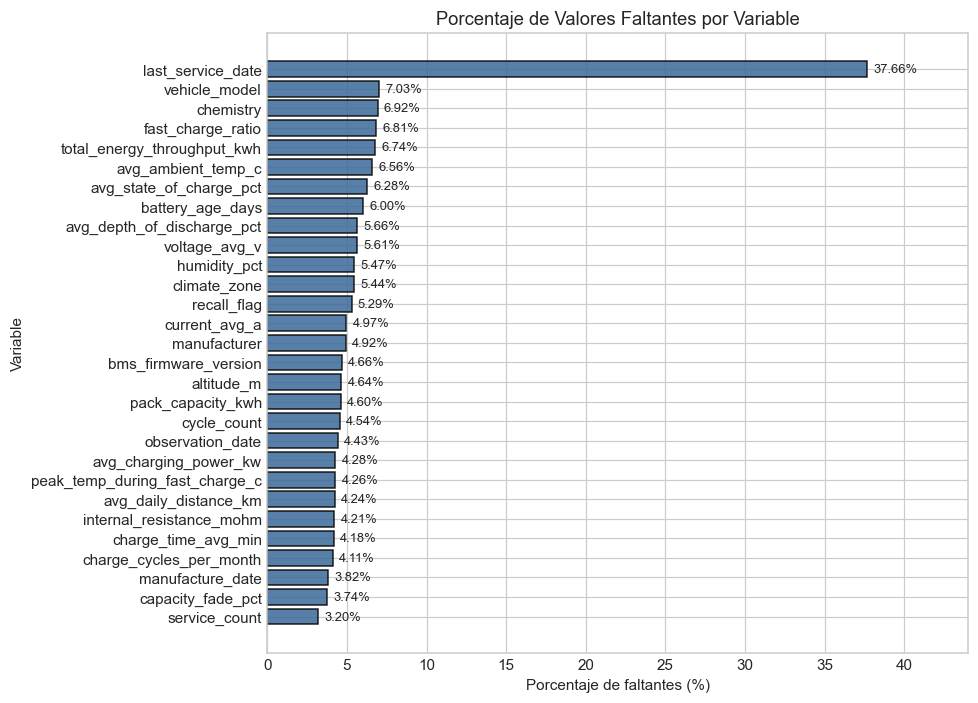

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110

# 1. Carga del dataset y dimensiones generales
csv_path = 'data/ev_battery_health.csv' if os.path.exists('data/ev_battery_health.csv') else 'ev_battery_health.csv'
df = pd.read_csv(csv_path)

print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")
print(f"observation_id duplicados: {df['observation_id'].duplicated().sum()}")
print(f"Baterías únicas (battery_id): {df['battery_id'].nunique():,}")
obs_batt = df['battery_id'].value_counts()
print(f"Observaciones por batería -> Mín: {obs_batt.min()}, Mediana: {obs_batt.median():.0f}, Media: {obs_batt.mean():.2f}, Máx: {obs_batt.max()}")

display(df.head(3))
display(df.tail(3))

# 2. Tabla de roles por variable
roles_map = {
    'battery_id': 'Identificador (Grupo)',
    'observation_id': 'Identificador (Registro)',
    'manufacture_date': 'Fecha',
    'observation_date': 'Fecha',
    'last_service_date': 'Fecha (ausencia estructural)',
    'chemistry': 'Categórica',
    'manufacturer': 'Categórica',
    'vehicle_model': 'Categórica',
    'climate_zone': 'Categórica',
    'bms_firmware_version': 'Categórica',
    'recall_flag': 'Categórica / Binaria',
    'failure_risk_label': 'Objetivo (Target)',
    'degradation_category': 'Otro objetivo / Posible fuga',
    'state_of_health_pct': 'Posible fuga (Diagnóstico SOH)',
    'capacity_fade_pct': 'Posible fuga (Complemento SOH)',
    'remaining_useful_life_cycles': 'Posible fuga (Diagnóstico RUL)',
    'internal_resistance_mohm': 'Numérica (Proxy SOH - auditar)'
}

tabla_roles = pd.DataFrame({
    'Variable': df.columns,
    'Tipo_Dato': df.dtypes.astype(str).values,
    'Rol': [roles_map.get(c, 'Numérica (Predictora)') for c in df.columns],
    'Unicos': df.nunique().values,
    'Nulos': df.isnull().sum().values,
    'Nulos_Pct': (df.isnull().mean() * 100).round(2).values
})
display(tabla_roles)

# 3. Auditoría de inconsistencias temporales y físicas
o_dt = pd.to_datetime(df['observation_date'], errors='coerce')
m_dt = pd.to_datetime(df['manufacture_date'], errors='coerce')
s_dt = pd.to_datetime(df['last_service_date'], errors='coerce')

print("\n--- Auditoría de inconsistencias ---")
print(f"observation_date < manufacture_date: {(o_dt < m_dt).sum()}")
print(f"observation_date < last_service_date: {(o_dt < s_dt).sum()}")
print(f"last_service_date < manufacture_date: {(s_dt < m_dt).sum()}")
diff_age = ((o_dt - m_dt).dt.days - df['battery_age_days']).dropna()
print(f"Diferencia (obs - mfg) vs battery_age_days -> Mín: {diff_age.min()}, Máx: {diff_age.max()}")

pct_cols = ['fast_charge_ratio', 'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct',
            'humidity_pct', 'capacity_fade_pct', 'state_of_health_pct']
for c in pct_cols:
    upper = 1.0 if c == 'fast_charge_ratio' else 100.0
    print(f"Fuera de rango [0, {upper}] en {c}: {((df[c] < 0) | (df[c] > upper)).sum()}")

print(f"avg_ambient_temp_c > 55°C: {(df['avg_ambient_temp_c'] > 55).sum()} (máx: {df['avg_ambient_temp_c'].max():.2f}°C)")
print(f"peak_temp_during_fast_charge_c > 65°C: {(df['peak_temp_during_fast_charge_c'] > 65).sum()} (máx: {df['peak_temp_during_fast_charge_c'].max():.2f}°C)")
print(f"peak_temp_during_fast_charge_c < avg_ambient_temp_c: {(df['peak_temp_during_fast_charge_c'] < df['avg_ambient_temp_c']).sum()}")
print(f"charge_time_avg_min > 600 min: {(df['charge_time_avg_min'] > 600).sum()} (máx: {df['charge_time_avg_min'].max():.2f} min)")

# 4. Gráfico de faltantes por variable
miss = tabla_roles[tabla_roles['Nulos'] > 0].sort_values('Nulos_Pct', ascending=True)
fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(miss['Variable'], miss['Nulos_Pct'], color='#3b6998', edgecolor='black', alpha=0.85)
for b in bars:
    w = b.get_width()
    ax.text(w + 0.4, b.get_y() + b.get_height()/2, f"{w:.2f}%", va='center', fontsize=8.5)
ax.set_title('Porcentaje de Valores Faltantes por Variable')
ax.set_xlabel('Porcentaje de faltantes (%)')
ax.set_ylabel('Variable')
ax.set_xlim(0, 44)
plt.tight_layout()
plt.show()

**Hallazgos del Paso 1:**
* **Datos repetidos por batería:** Hay 50.000 registros sin filas duplicadas, pero pertenecen a 2.600 baterías distintas (entre 7 y 37 mediciones por batería, promedio 19,23). Por eso, al dividir en entrenamiento y prueba debemos separar por `battery_id` para no evaluar el modelo con baterías que ya vio.
* **Valores faltantes:** `last_service_date` tiene un 37,66 % de nulos porque corresponde a baterías que nunca han ido a mantenimiento. El resto de variables con faltantes tienen entre 3,20 % y 7,03 %, mientras que las de diagnóstico (`state_of_health_pct`, `remaining_useful_life_cycles`, `degradation_category`) vienen completas.
* **Consistencia y fallas de sensor:** No hay fechas incoherentes ni porcentajes fuera de rango, y la diferencia entre fechas coincide exactamente con `battery_age_days`. Sin embargo, aparecen lecturas extremas propias de fallas de sensor: temperatura ambiente hasta 83,71 °C, temperatura pico de carga hasta 93,64 °C, tiempos de carga superiores a 1.000 minutos (hasta 1.232 min) y 3.348 casos donde la temperatura pico de carga es menor que la ambiente.

### Paso 2. Análisis de Valores Faltantes y Patrones de Ausencia

En este paso analizamos la distribución de los valores faltantes y evaluamos si ocurren al azar o siguen algún patrón:
1. Calculamos el porcentaje de nulos por variable y medimos la correlación entre sus indicadores de ausencia.
2. Aplicamos una prueba chi-cuadrado con corrección de Bonferroni para verificar si la falta de datos está relacionada con la clase objetivo (`failure_risk_label`).
3. Comprobamos la relación entre `last_service_date` y `service_count`, así como la posibilidad de recuperar atributos fijos de cada batería.

Correlación absoluta máxima entre indicadores de ausencia: 0.0133

=== PRUEBA CHI-CUADRADO DE AUSENCIA VS. CLASE OBJETIVO ===


,Variable,Nulos_Pct,Chi2,p_valor,p_Bonferroni,Relacion_con_Clase
26,last_service_date,37.66,3472.9364,0.0000,0.0000,Sí (p_adj < 0.05)
2,vehicle_model,7.03,11.5598,0.0031,0.0896,No (Independiente)
1,manufacturer,4.92,0.9601,0.6188,1.0000,No (Independiente)
0,chemistry,6.92,5.0123,0.0816,1.0000,No (Independiente)
4,manufacture_date,3.82,1.3557,0.5077,1.0000,No (Independiente)
5,observation_date,4.43,1.8667,0.3932,1.0000,No (Independiente)
6,battery_age_days,6.00,1.5915,0.4512,1.0000,No (Independiente)
3,pack_capacity_kwh,4.60,1.8113,0.4043,1.0000,No (Independiente)
8,climate_zone,5.44,0.7156,0.6992,1.0000,No (Independiente)
9,avg_daily_distance_km,4.24,2.9263,0.2315,1.0000,No (Independiente)



=== AUDITORÍA ESTRUCTURAL DE MANTENIMIENTO ===
last_service_date nulo cuando service_count == 0: 100.00%
last_service_date nulo cuando service_count > 0:  0.00%

=== CONSISTENCIA DE ATRIBUTOS FIJOS POR BATERÍA ===
chemistry            -> Máx valores distintos/batería: 1 | Nulos antes: 3,459 -> después: 0
manufacturer         -> Máx valores distintos/batería: 1 | Nulos antes: 2,461 -> después: 0
vehicle_model        -> Máx valores distintos/batería: 1 | Nulos antes: 3,515 -> después: 0
climate_zone         -> Máx valores distintos/batería: 1 | Nulos antes: 2,719 -> después: 0
pack_capacity_kwh    -> Máx valores distintos/batería: 1 | Nulos antes: 2,302 -> después: 0
manufacture_date     -> Máx valores distintos/batería: 1 | Nulos antes: 1,910 -> después: 0


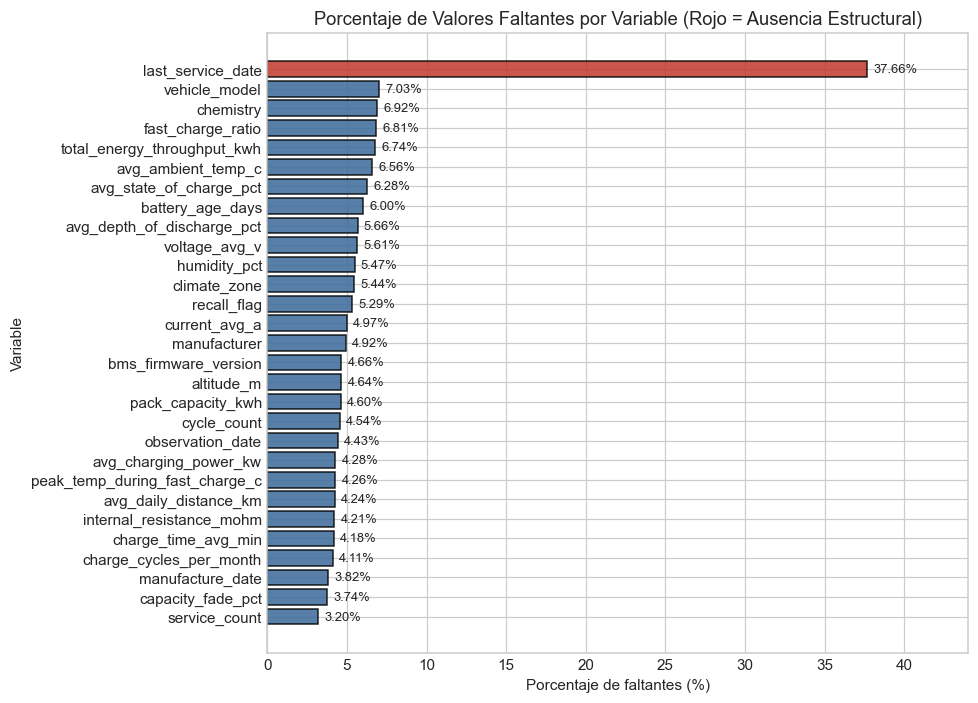

In [3]:
from scipy.stats import chi2_contingency

# 1. Porcentaje de faltantes por variable
cols_con_nulos = df.columns[df.isnull().any()].tolist()
miss_series = (df[cols_con_nulos].isnull().mean() * 100).sort_values(ascending=True)

# 2. Correlación entre indicadores de ausencia (matriz binaria 1=nulo, 0=presente)
ind_nulos = df[cols_con_nulos].isnull().astype(int)
corr_nulos = ind_nulos.corr()
np.fill_diagonal(corr_nulos.values, np.nan)
max_corr = np.nanmax(np.abs(corr_nulos.values))
print(f"Correlación absoluta máxima entre indicadores de ausencia: {max_corr:.4f}")

# 3. Prueba chi-cuadrado entre ausencia (nulo vs presente) y failure_risk_label (con Bonferroni)
resultados_chi2 = []
n_tests = len(cols_con_nulos)

for col in cols_con_nulos:
    tabla_cont = pd.crosstab(df[col].isnull(), df['failure_risk_label'])
    chi2_val, p_val, _, _ = chi2_contingency(tabla_cont)
    p_bonf = min(p_val * n_tests, 1.0)
    resultados_chi2.append({
        'Variable': col,
        'Nulos_Pct': round(df[col].isnull().mean() * 100, 2),
        'Chi2': round(chi2_val, 4),
        'p_valor': round(p_val, 4),
        'p_Bonferroni': round(p_bonf, 4),
        'Relacion_con_Clase': 'Sí (p_adj < 0.05)' if p_bonf < 0.05 else 'No (Independiente)'
    })

tabla_chi2 = pd.DataFrame(resultados_chi2).sort_values('p_Bonferroni', ascending=True)
print("\n=== PRUEBA CHI-CUADRADO DE AUSENCIA VS. CLASE OBJETIVO ===")
display(tabla_chi2)

# 4. Auditoría estructural de last_service_date vs service_count
print("\n=== AUDITORÍA ESTRUCTURAL DE MANTENIMIENTO ===")
print(f"last_service_date nulo cuando service_count == 0: {df.loc[df['service_count'] == 0, 'last_service_date'].isnull().mean()*100:.2f}%")
print(f"last_service_date nulo cuando service_count > 0:  {df.loc[df['service_count'] > 0, 'last_service_date'].isnull().mean()*100:.2f}%")

# 5. Revisión de atributos fijos por batería (battery_id)
atributos_fijos = ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'pack_capacity_kwh', 'manufacture_date']
print("\n=== CONSISTENCIA DE ATRIBUTOS FIJOS POR BATERÍA ===")
for col in atributos_fijos:
    max_unicos_por_bateria = df.groupby('battery_id')[col].nunique(dropna=True).max()
    nulos_antes = df[col].isnull().sum()
    nulos_despues = df.groupby('battery_id')[col].transform(lambda s: s.ffill().bfill()).isnull().sum()
    print(f"{col:20s} -> Máx valores distintos/batería: {max_unicos_por_bateria} | Nulos antes: {nulos_antes:,} -> después: {nulos_despues:,}")

# 6. Gráfico de barras horizontales de faltantes
fig, ax = plt.subplots(figsize=(9, 6.5))
colores = ['#c0392b' if c == 'last_service_date' else '#3b6998' for c in miss_series.index]
bars = ax.barh(miss_series.index, miss_series.values, color=colores, edgecolor='black', alpha=0.85)
for b in bars:
    w = b.get_width()
    ax.text(w + 0.4, b.get_y() + b.get_height()/2, f"{w:.2f}%", va='center', fontsize=8.5)
ax.set_title('Porcentaje de Valores Faltantes por Variable (Rojo = Ausencia Estructural)')
ax.set_xlabel('Porcentaje de faltantes (%)')
ax.set_ylabel('Variable')
ax.set_xlim(0, 44)
plt.tight_layout()
plt.show()

**Hallazgos del Paso 2:**
* **Ausencias al azar en las mediciones:** Las 28 variables con faltantes menores (entre 3,20 % y 7,03 %) no muestran correlación entre sí ni relación significativa con el riesgo de falla en la prueba chi-cuadrado (p-valores ajustados > 0,05), por lo que no se elimina ninguna y se imputarán con la mediana dentro del pipeline.
* **Ausencia estructural en mantenimiento:** `last_service_date` tiene un 37,66 % de nulos porque falta el 100 % de las veces cuando `service_count = 0` (baterías sin historial de taller). Por eso se transformará en `dias_desde_ultimo_servicio` junto con un indicador binario `sin_fecha_servicio`.
* **Recuperación de datos fijos del pack:** Variables propias de cada batería como `chemistry`, `manufacturer`, `vehicle_model`, `climate_zone`, `pack_capacity_kwh` y `manufacture_date` son constantes por `battery_id`, permitiendo completar prácticamente todos sus nulos a partir de otros registros de la misma batería sin riesgo de fuga.

### Paso 3. Partición Agrupada por Batería (Entrenamiento, Prueba y Validación Cruzada)

Antes de cruzar las variables predictoras con la variable objetivo, separamos el conjunto de prueba independiente agrupando por `battery_id` mediante `StratifiedGroupKFold` (~80 % de baterías para entrenamiento y ~20 % para prueba). De igual forma, dejamos fijos los 5 pliegues agrupados de validación cruzada para garantizar que ninguna batería aparezca simultáneamente en entrenamiento y evaluación.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_STATE = 42
TARGET_COL = 'failure_risk_label'
GROUP_COL = 'battery_id'
ORDEN_CLASES = ['Low', 'Medium', 'High']

# 1. Separación inicial 80/20 agrupada por battery_id y estratificada por clase
sgkf_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf_outer.split(df, df[TARGET_COL], groups=df[GROUP_COL]))

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

# 2. Verificación estricta de no solapamiento de baterías
baterias_train = set(train_df[GROUP_COL].unique())
baterias_test = set(test_df[GROUP_COL].unique())
solapamiento = len(baterias_train.intersection(baterias_test))
assert solapamiento == 0, "¡Error: hay baterías compartidas entre entrenamiento y prueba!"

print(f"Baterías compartidas entre Train y Test: {solapamiento} (Verificado)")
print(f"Total Train -> {len(train_df):,} filas | {len(baterias_train):,} baterías ({len(baterias_train)/df[GROUP_COL].nunique()*100:.2f}%)")
print(f"Total Test  -> {len(test_df):,} filas | {len(baterias_test):,} baterías ({len(baterias_test)/df[GROUP_COL].nunique()*100:.2f}%)")

# 3. Fijar los 5 pliegues agrupados sobre train_df para reutilizarlos en todo el proyecto
sgkf_inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(sgkf_inner.split(train_df, train_df[TARGET_COL], groups=train_df[GROUP_COL]))

# 4. Tabla resumen de filas, baterías y distribución de clases en Train, Test y cada pliegue
def resumir_particion(nombre, sub_df):
    dist = sub_df[TARGET_COL].value_counts(normalize=True) * 100
    return {
        'Particion': nombre,
        'Filas': len(sub_df),
        'Baterias': sub_df[GROUP_COL].nunique(),
        'Low_Pct': round(dist.get('Low', 0.0), 2),
        'Medium_Pct': round(dist.get('Medium', 0.0), 2),
        'High_Pct': round(dist.get('High', 0.0), 2)
    }

filas_resumen = [
    resumir_particion('Dataset Completo', df),
    resumir_particion('Entrenamiento (Train)', train_df),
    resumir_particion('Prueba (Test)', test_df)
]

for i, (tr_f, va_f) in enumerate(cv_splits, start=1):
    # Verificar que cada pliegue tampoco comparta baterías
    assert len(set(train_df.iloc[tr_f][GROUP_COL]).intersection(set(train_df.iloc[va_f][GROUP_COL]))) == 0
    filas_resumen.append(resumir_particion(f'Pliegue Val {i}', train_df.iloc[va_f]))

tabla_particiones = pd.DataFrame(filas_resumen)
display(tabla_particiones)

Baterías compartidas entre Train y Test: 0 (Verificado)
Total Train -> 39,921 filas | 2,075 baterías (79.81%)
Total Test  -> 10,079 filas | 525 baterías (20.19%)


,Particion,Filas,Baterias,Low_Pct,Medium_Pct,High_Pct
0,Dataset Completo,50000,2600,85.47,8.82,5.71
1,Entrenamiento (Train),39921,2075,85.40,8.82,5.78
2,Prueba (Test),10079,525,85.73,8.81,5.46
3,Pliegue Val 1,8016,416,86.22,8.22,5.56
4,Pliegue Val 2,8073,414,88.02,7.72,4.26
5,Pliegue Val 3,8011,414,84.81,9.71,5.48
6,Pliegue Val 4,7914,418,84.12,9.45,6.43
7,Pliegue Val 5,7907,413,83.80,9.02,7.18


**Hallazgos del Paso 3:**
* **Cero fuga entre grupos:** La partición separó exactamente 2.075 baterías (39.921 filas) para entrenamiento y 525 baterías (10.079 filas) para prueba, confirmando que ninguna batería aparece en ambos conjuntos ni se repite entre los 5 pliegues de validación cruzada.
* **Proporción de clases conservada:** Tanto el entrenamiento (85,40 % Low / 8,82 % Medium / 5,78 % High) como la prueba (85,73 % / 8,81 % / 5,46 %) y los 5 pliegues mantienen prácticamente intacta la distribución original del dataset, dejando listo un esquema de validación limpio y reutilizable.

### Paso 4. Distribución de la Variable Objetivo y Desbalance de Clases

Analizamos sobre el conjunto de entrenamiento (`train_df`) la proporción de cada nivel de riesgo (`Low`, `Medium`, `High`), evaluamos el desempeño de un clasificador trivial que siempre predice la clase mayoritaria y revisamos cuántas categorías distintas de riesgo experimenta cada batería a lo largo de su vida útil.

,Clase,Conteo,Porcentaje (%),Ratio_vs_High
0,Low,34094,85.40,14.78
1,Medium,3521,8.82,1.53
2,High,2306,5.78,1.00



--- Línea base trivial (predecir siempre 'Low') en Train ---
Accuracy:          0.8540
F1 macro:          0.3071
Balanced Accuracy: 0.3333
MCC:               0.0000

--- Evolución del riesgo por batería (Train) ---
Baterías con 1 clase(s) distinta(s): 1,193 (57.49%)
Baterías con 2 clase(s) distinta(s): 438 (21.11%)
Baterías con 3 clase(s) distinta(s): 444 (21.40%)


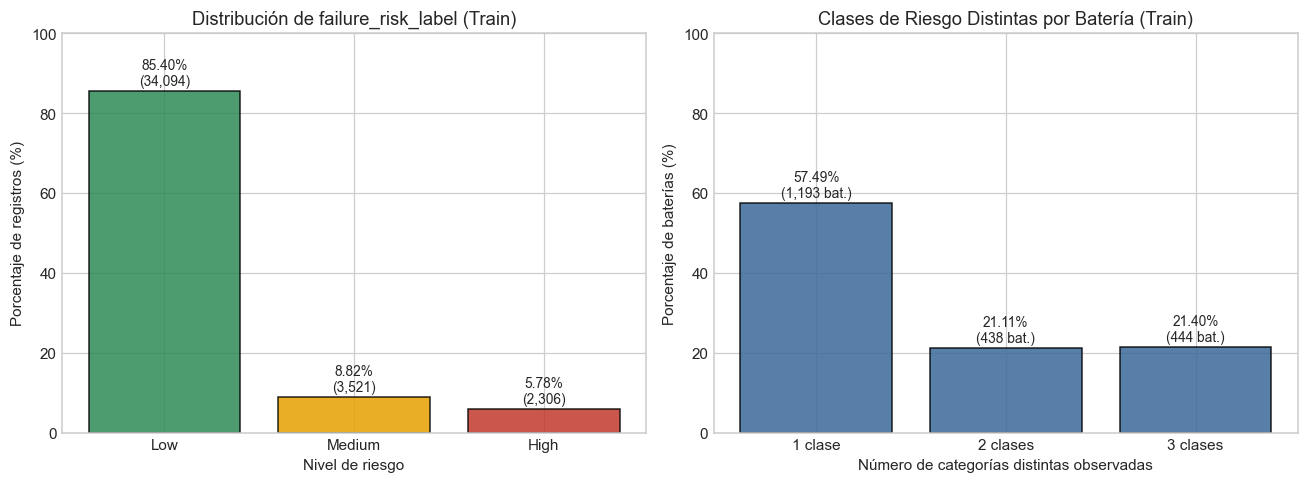

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, matthews_corrcoef

# 1. Conteo y porcentajes en el conjunto de entrenamiento
conteo_clases = train_df[TARGET_COL].value_counts().reindex(ORDEN_CLASES)
pct_clases = (conteo_clases / len(train_df) * 100).round(2)

resumen_target = pd.DataFrame({
    'Clase': ORDEN_CLASES,
    'Conteo': conteo_clases.values,
    'Porcentaje (%)': pct_clases.values,
    'Ratio_vs_High': (conteo_clases.values / conteo_clases['High']).round(2)
})
display(resumen_target)

# 2. Evaluación del clasificador trivial (siempre predice 'Low')
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(train_df.drop(columns=[TARGET_COL]), train_df[TARGET_COL])
y_dummy = dummy.predict(train_df.drop(columns=[TARGET_COL]))

print("\n--- Línea base trivial (predecir siempre 'Low') en Train ---")
print(f"Accuracy:          {accuracy_score(train_df[TARGET_COL], y_dummy):.4f}")
print(f"F1 macro:          {f1_score(train_df[TARGET_COL], y_dummy, average='macro'):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(train_df[TARGET_COL], y_dummy):.4f}")
print(f"MCC:               {matthews_corrcoef(train_df[TARGET_COL], y_dummy):.4f}")

# 3. Número de clases distintas que experimenta cada batería en el tiempo
clases_por_bateria = train_df.groupby(GROUP_COL)[TARGET_COL].nunique().value_counts().sort_index()
pct_baterias_clases = (clases_por_bateria / train_df[GROUP_COL].nunique() * 100).round(2)

print("\n--- Evolución del riesgo por batería (Train) ---")
for n_clases, cnt in clases_por_bateria.items():
    print(f"Baterías con {n_clases} clase(s) distinta(s): {cnt:,} ({pct_baterias_clases[n_clases]:.2f}%)")

# 4. Gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico A: Distribución de clases
colores_clase = ['#2e8b57', '#e69f00', '#c0392b']
bars1 = axes[0].bar(ORDEN_CLASES, pct_clases.values, color=colores_clase, edgecolor='black', alpha=0.85)
for b, cnt in zip(bars1, conteo_clases.values):
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 1.5, f"{h:.2f}%\n({cnt:,})", ha='center', fontsize=9)
axes[0].set_title('Distribución de failure_risk_label (Train)')
axes[0].set_xlabel('Nivel de riesgo')
axes[0].set_ylabel('Porcentaje de registros (%)')
axes[0].set_ylim(0, 100)

# Gráfico B: Cantidad de clases distintas por batería
etiquetas_x = [f"{k} clase" if k == 1 else f"{k} clases" for k in clases_por_bateria.index]
bars2 = axes[1].bar(etiquetas_x, pct_baterias_clases.values, color='#3b6998', edgecolor='black', alpha=0.85)
for b, cnt in zip(bars2, clases_por_bateria.values):
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 1.5, f"{h:.2f}%\n({cnt:,} bat.)", ha='center', fontsize=9)
axes[1].set_title('Clases de Riesgo Distintas por Batería (Train)')
axes[1].set_xlabel('Número de categorías distintas observadas')
axes[1].set_ylabel('Porcentaje de baterías (%)')
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

**Hallazgos del Paso 4:**
* **Desbalance fuerte de clases:** En entrenamiento hay 85,40 % de registros `Low` (34.094), 8,82 % `Medium` (3.521) y apenas 5,78 % `High` (2.306), es decir, casi 15 registros de riesgo bajo por cada registro de riesgo alto.
* **Por qué Accuracy engaña:** Un modelo trivial que siempre prediga `Low` alcanza un Accuracy de 0,8540 sin detectar ni una sola falla, mientras que su F1 macro cae a 0,3071 (y MCC a 0,0000). Por eso usaremos F1 macro como métrica principal porque permite evaluar las tres clases por igual, combinando Precision y Recall de cada una.
* **El riesgo cambia con el desgaste:** El 42,51 % de las baterías (21,11 % con 2 clases y 21,40 % con 3 clases) cambian de nivel de riesgo a lo largo de sus mediciones, confirmando que la etiqueta evoluciona con el deterioro operativo y no es una característica fija de fábrica.

### Paso 5. Análisis Exploratorio de Variables Numéricas, Categóricas y Relaciones (Train)

Exploramos exclusivamente sobre el conjunto de entrenamiento (`train_df`) las distribuciones de las variables numéricas y categóricas, así como su asociación con `failure_risk_label` utilizando medidas de tamaño del efecto ($V$ de Cramér, correlación de Spearman y $\varepsilon^2$ de Kruskal-Wallis) para identificar señales discriminativas y redundancias sin interpretarlas como causalidad.

,Variable,Media,Mediana,Desv_Std,Q1,Q3,Asimetria,Atipicos_IQR_Pct
0,pack_capacity_kwh,72.68,72.50,14.39,62.50,82.80,-0.07,0.00
1,battery_age_days,564.39,429.00,479.46,173.00,850.00,0.96,1.15
2,cycle_count,579.47,378.00,603.73,140.00,818.00,1.83,4.89
3,avg_daily_distance_km,50.46,39.60,39.57,22.70,66.60,1.83,4.61
4,avg_charging_power_kw,32.02,28.70,17.78,19.00,41.80,1.00,2.38
5,fast_charge_ratio,0.29,0.27,0.17,0.16,0.41,0.56,0.56
6,avg_depth_of_discharge_pct,64.90,65.20,15.46,54.30,75.70,-0.14,0.37
7,avg_state_of_charge_pct,67.56,67.80,9.99,60.80,74.50,-0.10,0.33
8,charge_cycles_per_month,20.23,19.00,10.16,12.70,26.60,0.53,0.78
9,total_energy_throughput_kwh,39136.76,24625.15,42683.98,9055.83,54607.08,2.10,5.22


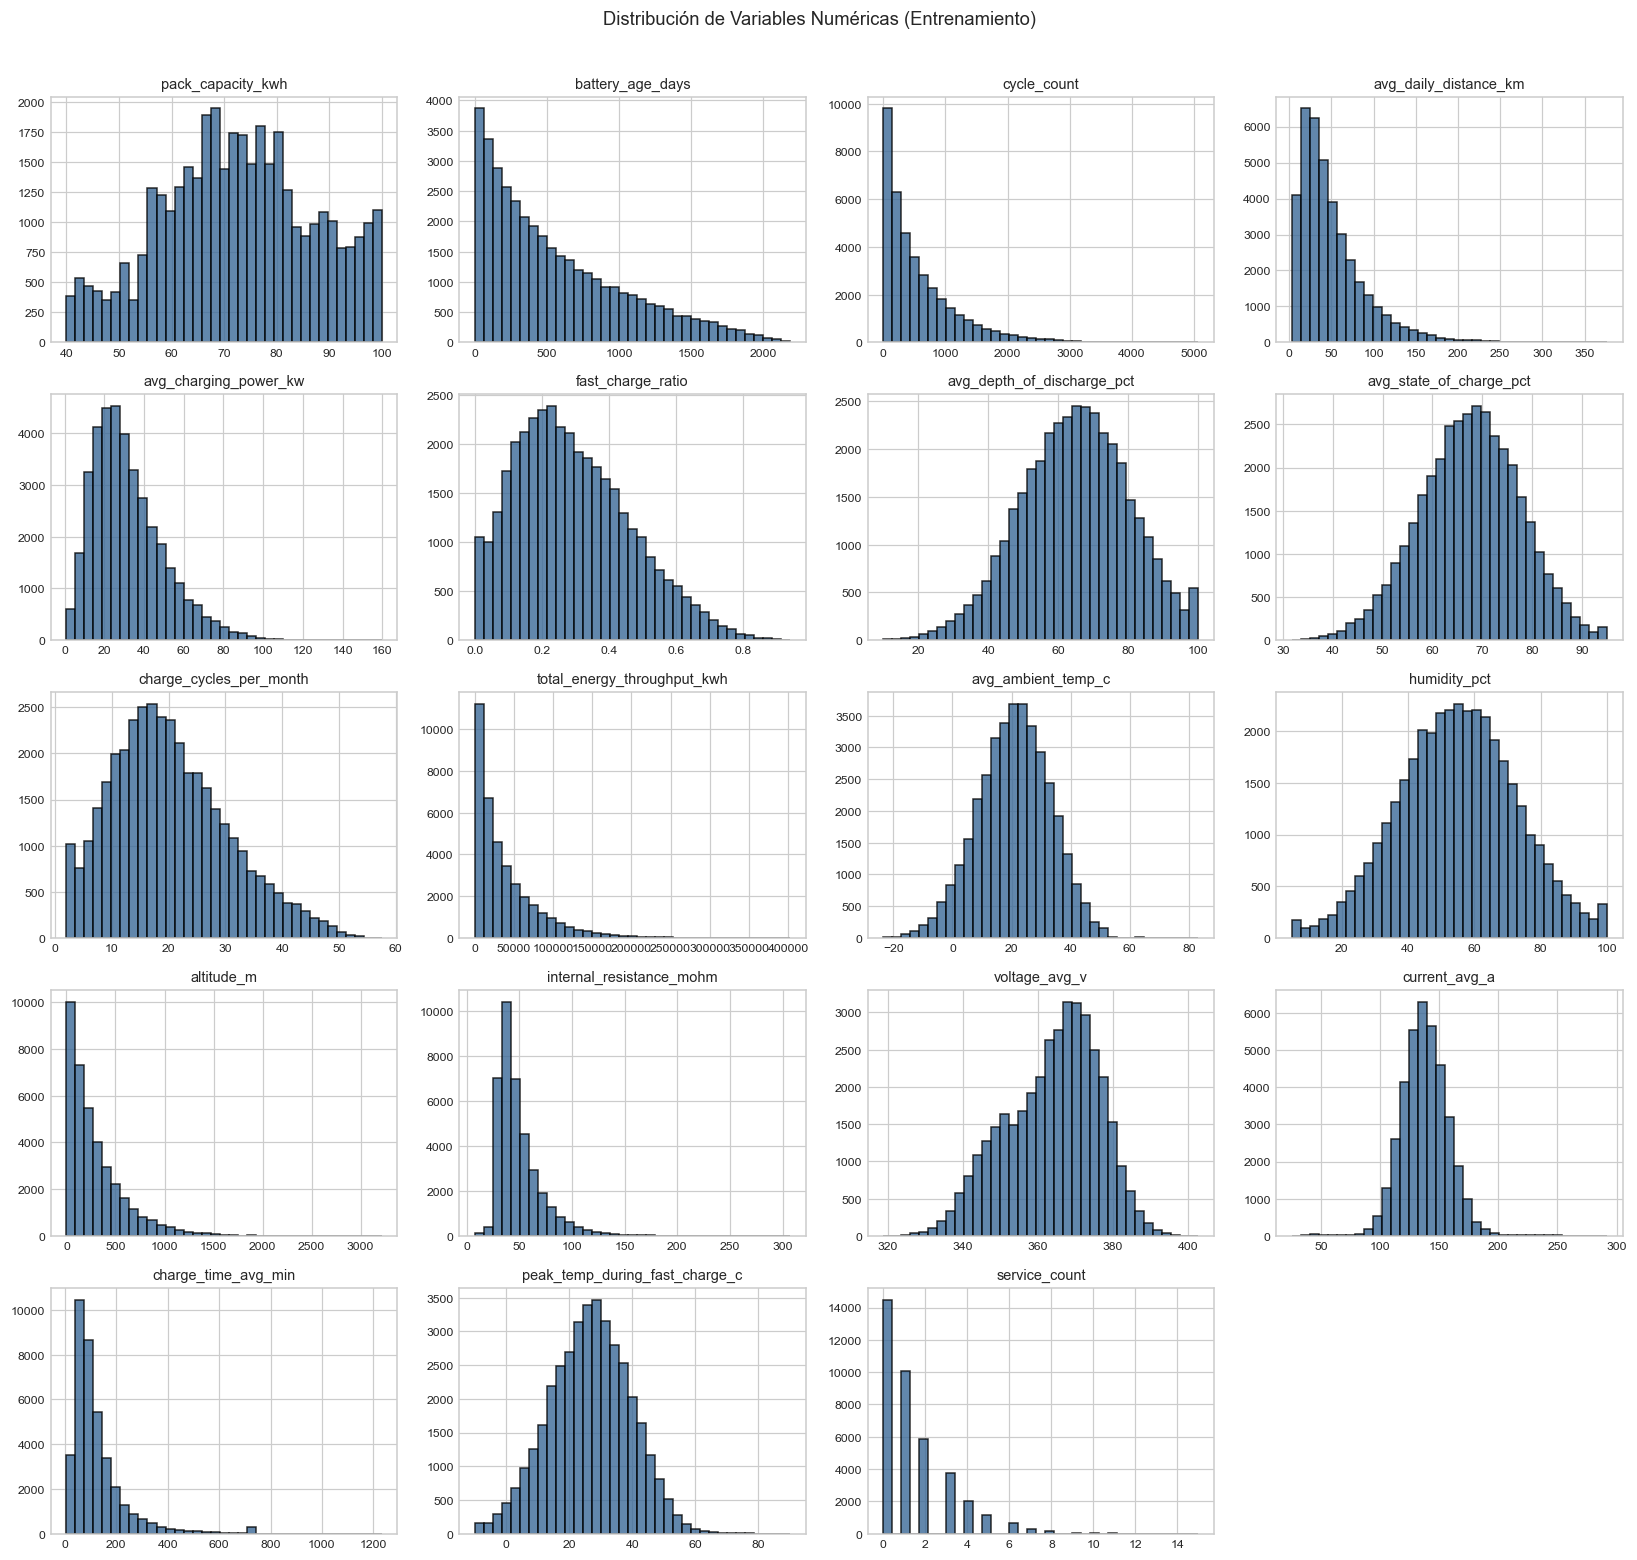

,Variable,Categorias,Chi2,V_Cramer
0,chemistry,4,3115.81,0.2048
5,recall_flag,2,99.85,0.0514
1,manufacturer,8,83.89,0.0332
3,climate_zone,5,47.71,0.0251
2,vehicle_model,8,37.93,0.0226
4,bms_firmware_version,5,3.69,0.0070


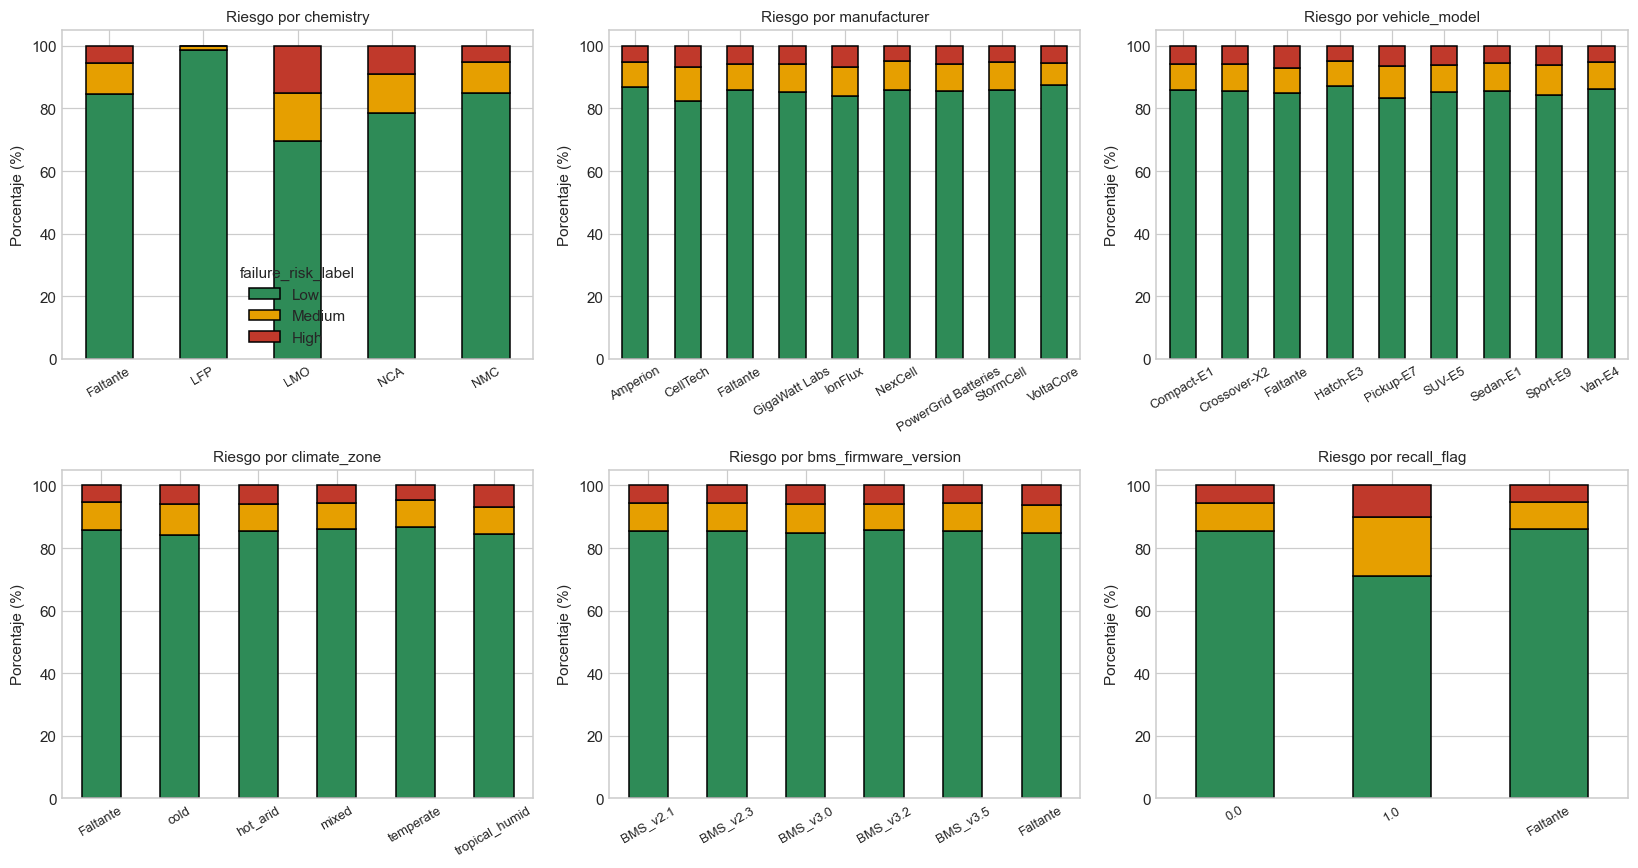

,Variable,Kruskal_H,Epsilon2
13,internal_resistance_mohm,13135.50,0.3434
2,cycle_count,11342.58,0.2975
9,total_energy_throughput_kwh,9913.24,0.2663
1,battery_age_days,9569.07,0.2552
18,service_count,5734.17,0.1483
8,charge_cycles_per_month,1832.47,0.0479
3,avg_daily_distance_km,876.33,0.0229
14,voltage_avg_v,101.32,0.0026
0,pack_capacity_kwh,57.18,0.0014
6,avg_depth_of_discharge_pct,29.50,0.0007


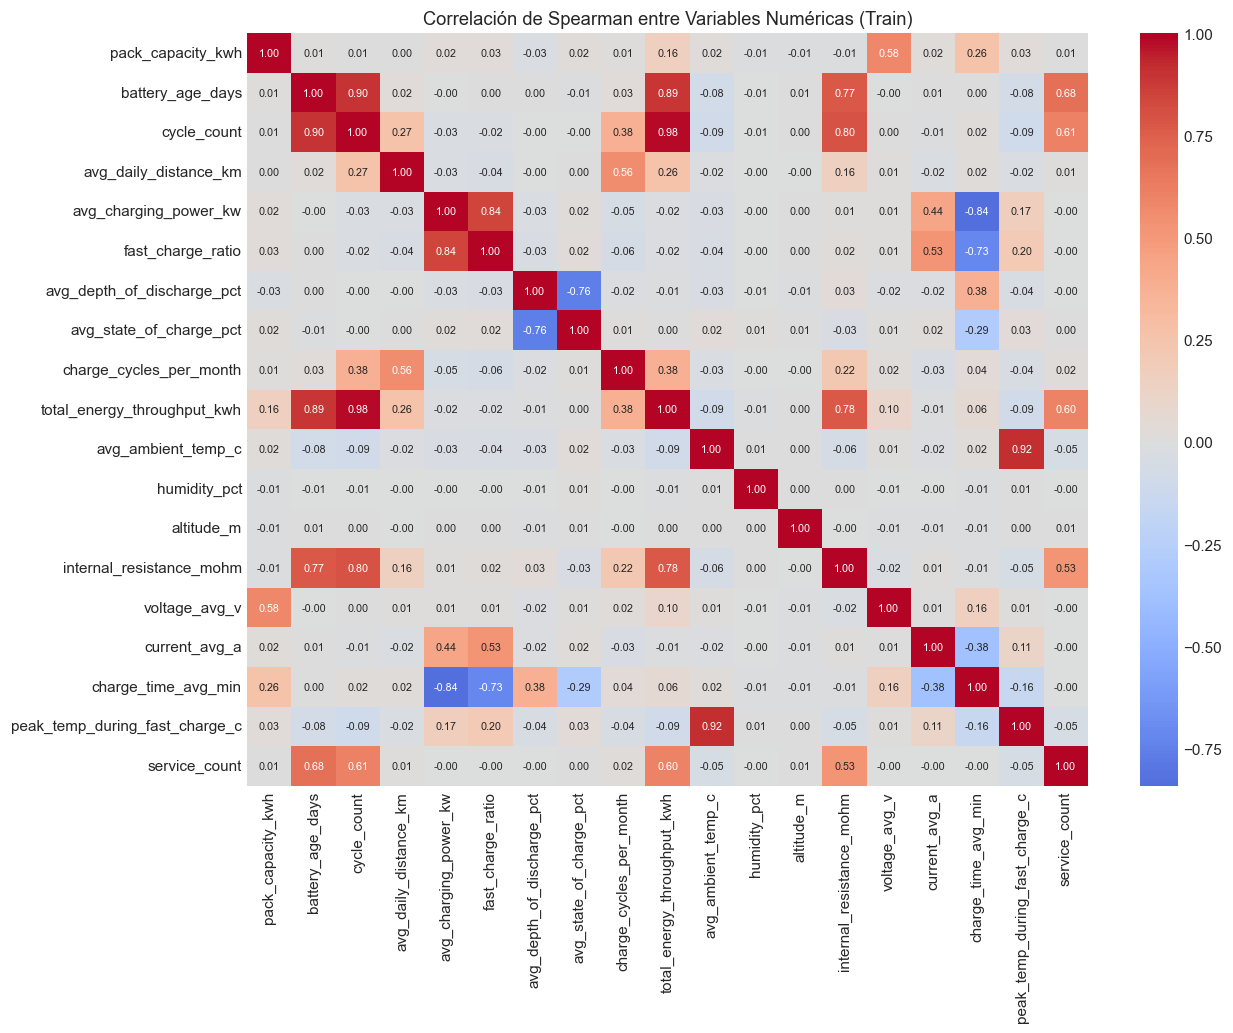

In [6]:
from scipy.stats import chi2_contingency, kruskal

# Definir columnas numéricas y categóricas operativas
cols_excluir = ['battery_id', 'observation_id', 'manufacture_date', 'observation_date', 'last_service_date',
                'failure_risk_label', 'degradation_category', 'state_of_health_pct',
                'capacity_fade_pct', 'remaining_useful_life_cycles']

cat_cols = ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'bms_firmware_version', 'recall_flag']
num_cols = [c for c in train_df.columns if c not in cols_excluir + cat_cols]

# 5.1. Resumen estadístico e histogramas de numéricas
stats_num = []
for c in num_cols:
    s = train_df[c].dropna()
    q1, med, q3 = np.percentile(s, [25, 50, 75])
    iqr = q3 - q1
    out_pct = ((s < (q1 - 1.5 * iqr)) | (s > (q3 + 1.5 * iqr))).mean() * 100
    stats_num.append({
        'Variable': c, 'Media': round(s.mean(), 2), 'Mediana': round(med, 2),
        'Desv_Std': round(s.std(), 2), 'Q1': round(q1, 2), 'Q3': round(q3, 2),
        'Asimetria': round(s.skew(), 2), 'Atipicos_IQR_Pct': round(out_pct, 2)
    })
display(pd.DataFrame(stats_num))

n_cols_grid = 4
n_rows_grid = int(np.ceil(len(num_cols) / n_cols_grid))
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(15, n_rows_grid * 2.8))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    axes[i].hist(train_df[c].dropna(), bins=35, color='#3b6998', edgecolor='black', alpha=0.8)
    axes[i].set_title(c, fontsize=9.5)
    axes[i].tick_params(labelsize=8)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.suptitle('Distribución de Variables Numéricas (Entrenamiento)', y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

# 5.2. Tabla V de Cramér y barras apiladas al 100 % por categoría
stats_cat = []
for c in cat_cols:
    ct = pd.crosstab(train_df[c].dropna(), train_df.loc[train_df[c].notna(), TARGET_COL])
    chi2_val, p_val, _, _ = chi2_contingency(ct)
    n, (r, k) = ct.sum().sum(), ct.shape
    v_cramer = np.sqrt(chi2_val / (n * (min(r - 1, k - 1))))
    stats_cat.append({'Variable': c, 'Categorias': r, 'Chi2': round(chi2_val, 2), 'V_Cramer': round(v_cramer, 4)})
display(pd.DataFrame(stats_cat).sort_values('V_Cramer', ascending=False))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
colores_clase = ['#2e8b57', '#e69f00', '#c0392b']
for i, c in enumerate(cat_cols):
    ct_pct = pd.crosstab(train_df[c].fillna('Faltante'), train_df[TARGET_COL], normalize='index')[ORDEN_CLASES] * 100
    ct_pct.plot(kind='bar', stacked=True, color=colores_clase, edgecolor='black', ax=axes[i], legend=(i == 0))
    axes[i].set_title(f'Riesgo por {c}', fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Porcentaje (%)')
    axes[i].tick_params(axis='x', rotation=30, labelsize=8.5)
plt.tight_layout()
plt.show()

# 5.3. Tabla Kruskal-Wallis (Epsilon^2) y mapa de calor de Spearman
kw_stats = []
for c in num_cols:
    sub = train_df[[c, TARGET_COL]].dropna()
    grupos = [sub.loc[sub[TARGET_COL] == cl, c].values for cl in ORDEN_CLASES]
    h_stat, _ = kruskal(*grupos)
    eps2 = max(0.0, (h_stat - len(ORDEN_CLASES) + 1) / (len(sub) - len(ORDEN_CLASES)))
    kw_stats.append({'Variable': c, 'Kruskal_H': round(h_stat, 2), 'Epsilon2': round(eps2, 4)})
display(pd.DataFrame(kw_stats).sort_values('Epsilon2', ascending=False))

corr_spearman = train_df[num_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr_spearman, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Correlación de Spearman entre Variables Numéricas (Train)')
plt.tight_layout()
plt.show()

**Hallazgos del Paso 5:**
* **El desgaste acumulado domina la separación:** Según la prueba de Kruskal-Wallis, las variables que mejor distinguen los niveles de riesgo miden deterioro acumulado: resistencia interna (epsilon² = 0,343), ciclos acumulados (0,298), energía total transferida (0,266) y edad de la batería (0,255), seguidas por el número de mantenimientos (0,148). En contraste, las variables de intensidad instantánea (temperatura, corriente, potencia de carga) no separan las clases por sí solas.
* **Categóricas:** Solo la química de la batería (`chemistry`, V de Cramér = 0,205) muestra una asociación clara (las baterías LMO concentran mucho más riesgo que las LFP), mientras que fabricante, modelo o firmware apenas varían entre clases.
* **Redundancia y preprocesamiento:** Existen bloques altamente correlacionados (como `cycle_count` con energía total, rho = 0,98, y temperatura ambiente con temperatura pico, rho = 0,92) y colas largas por fallas de sensor (`charge_time_avg_min` con 6,84 % de atípicos). Por eso recortaremos extremos en los percentiles 0,5 y 99,5 y estandarizaremos dentro del pipeline para los modelos sensibles a escala. (Nota: estas asociaciones reflejan patrones observados en los datos, no relaciones causales).

### Paso 6. Auditoría de Fuga de Información y Análisis de Sensibilidad

Evaluamos qué variables contienen información derivada o equivalente al diagnóstico final (`state_of_health_pct`, `capacity_fade_pct`, `remaining_useful_life_cycles`, `degradation_category`) entrenando un árbol de decisión superficial (profundidad 4) de forma univariada con validación agrupada. Posteriormente comparamos cuatro escenarios de selección de variables (A: principal, B: sin resistencia interna, C1: incluyendo SOH/fade/RUL y C2: todas las variables) mediante F1 macro en validación cruzada.

Error máximo en capacity_fade_pct + state_of_health_pct = 100: 0.000000

=== AUDITORÍA UNIVARIADA DE POSIBLE FUGA (ÁRBOL PROFUNDIDAD 4) ===


,Variable,Rho_con_SOH,F1_Macro_Arbol_D4,Std_Pliegues
0,state_of_health_pct,1.0000,0.8189,0.0095
1,capacity_fade_pct,-1.0000,0.7597,0.0190
4,internal_resistance_mohm,-0.8996,0.7422,0.0144
2,remaining_useful_life_cycles,0.6671,0.6696,0.0140
5,cycle_count,-0.9063,0.6144,0.0181
3,degradation_category,NaN,0.5768,0.0078
7,battery_age_days,-0.8821,0.5194,0.0188
6,total_energy_throughput_kwh,-0.8872,0.5111,0.0251



=== ANÁLISIS DE SENSIBILIDAD POR ESCENARIO (VALIDACIÓN CRUZADA AGRUPADA) ===


,Escenario,Modelo,F1_Macro_Media,IC95
0,A: Principal (sin SOH/RUL),Regresión Logística,0.8040,0.0100
1,A: Principal (sin SOH/RUL),Random Forest,0.8342,0.0053
2,B: Sin resistencia interna,Regresión Logística,0.7418,0.0156
3,B: Sin resistencia interna,Random Forest,0.7634,0.0143
4,"C1: Con SOH, fade y RUL",Regresión Logística,0.8516,0.0049
5,"C1: Con SOH, fade y RUL",Random Forest,0.8667,0.0095
6,C2: Todo (incluye deg_cat),Regresión Logística,0.8511,0.0048
7,C2: Todo (incluye deg_cat),Random Forest,0.8673,0.0061


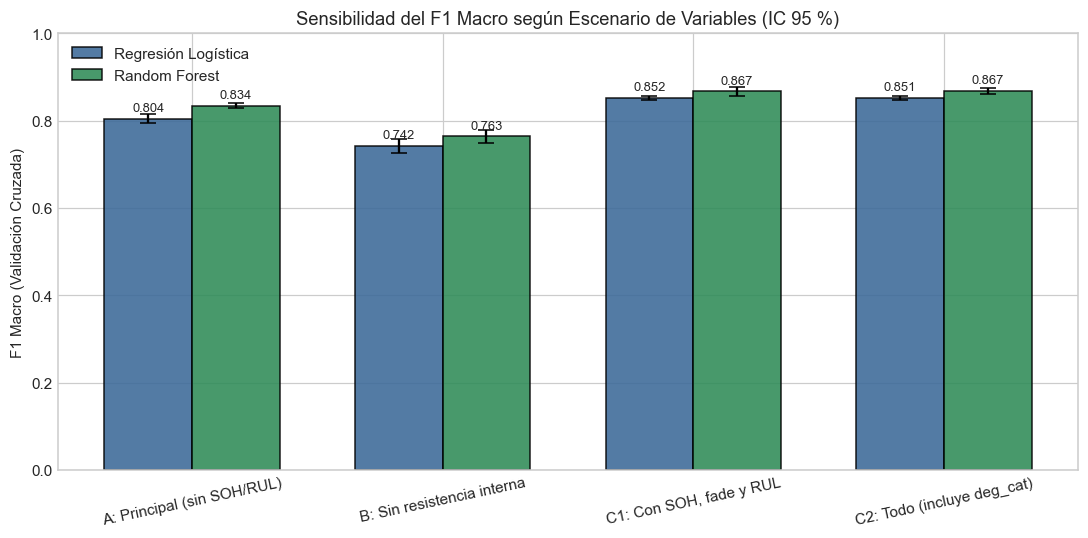

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# ==============================================================================
# 6.1. IDENTIDADES, CORRELACIÓN CON SOH Y ÁRBOL UNIVARIADO (PROFUNDIDAD 4)
# ==============================================================================
# Verificar identidad capacity_fade_pct = 100 - state_of_health_pct
mask_valido = train_df['capacity_fade_pct'].notna() & train_df['state_of_health_pct'].notna()
diff_soh = np.abs((train_df.loc[mask_valido, 'capacity_fade_pct'] + train_df.loc[mask_valido, 'state_of_health_pct']) - 100.0)
print(f"Error máximo en capacity_fade_pct + state_of_health_pct = 100: {diff_soh.max():.6f}")

# Correlación de Spearman de las candidatas con state_of_health_pct
candidatas = [
    'state_of_health_pct', 'capacity_fade_pct', 'remaining_useful_life_cycles',
    'degradation_category', 'internal_resistance_mohm', 'cycle_count',
    'total_energy_throughput_kwh', 'battery_age_days'
]

resultados_univar = []
for col in candidatas:
    if col == 'degradation_category':
        pipe_u = Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore')),
            ('clf', DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE))
        ])
        rho_soh = np.nan
    else:
        pipe_u = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('clf', DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE))
        ])
        rho_soh = round(train_df[col].corr(train_df['state_of_health_pct'], method='spearman'), 4)

    scores = cross_val_score(
        pipe_u, train_df[[col]], train_df[TARGET_COL],
        cv=cv_splits, scoring='f1_macro', n_jobs=-1
    )
    resultados_univar.append({
        'Variable': col,
        'Rho_con_SOH': rho_soh,
        'F1_Macro_Arbol_D4': round(scores.mean(), 4),
        'Std_Pliegues': round(scores.std(), 4)
    })

tabla_fuga = pd.DataFrame(resultados_univar).sort_values('F1_Macro_Arbol_D4', ascending=False)
print("\n=== AUDITORÍA UNIVARIADA DE POSIBLE FUGA (ÁRBOL PROFUNDIDAD 4) ===")
display(tabla_fuga)

# ==============================================================================
# 6.2. ANÁLISIS DE SENSIBILIDAD POR ESCENARIOS (A, B, C1, C2)
# ==============================================================================
# Preparar copia temporal de train_df con atributos fijos recuperados y fechas derivadas
df_sens = train_df.copy()
atributos_fijos = ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'pack_capacity_kwh', 'manufacture_date']
for col in atributos_fijos:
    df_sens[col] = df_sens.groupby(GROUP_COL)[col].transform(lambda s: s.ffill().bfill())

obs_dt = pd.to_datetime(df_sens['observation_date'], errors='coerce')
srv_dt = pd.to_datetime(df_sens['last_service_date'], errors='coerce')
df_sens['sin_fecha_servicio'] = df_sens['last_service_date'].isnull().astype(int)
df_sens['dias_desde_ultimo_servicio'] = (obs_dt - srv_dt).dt.days.fillna(-1)

# Definir columnas base y escenarios
cols_id_fecha = ['battery_id', 'observation_id', 'manufacture_date', 'observation_date', 'last_service_date', TARGET_COL]
cols_fuga_soh = ['state_of_health_pct', 'capacity_fade_pct', 'remaining_useful_life_cycles']

cols_todas = [c for c in df_sens.columns if c not in cols_id_fecha]
cols_A = [c for c in cols_todas if c not in cols_fuga_soh + ['degradation_category']]
cols_B = [c for c in cols_A if c != 'internal_resistance_mohm']
cols_C1 = cols_A + cols_fuga_soh
cols_C2 = cols_todas  # Incluye SOH, fade, RUL y degradation_category

escenarios = {
    'A: Principal (sin SOH/RUL)': cols_A,
    'B: Sin resistencia interna': cols_B,
    'C1: Con SOH, fade y RUL': cols_C1,
    'C2: Todo (incluye deg_cat)': cols_C2
}

modelos_sens = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=12, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
}

resultados_sens = []
for nombre_esc, cols_esc in escenarios.items():
    cat_esc = [c for c in cols_esc if df_sens[c].dtype == 'object' or c in ['recall_flag', 'sin_fecha_servicio']]
    num_esc = [c for c in cols_esc if c not in cat_esc]

    preproc = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_esc),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_esc)
    ])

    for nombre_mod, mod in modelos_sens.items():
        pipe = Pipeline([('prep', preproc), ('clf', mod)])
        scores = cross_val_score(pipe, df_sens[cols_esc], df_sens[TARGET_COL], cv=cv_splits, scoring='f1_macro', n_jobs=-1)
        ic95 = 1.96 * (scores.std(ddof=1) / np.sqrt(len(scores)))
        resultados_sens.append({
            'Escenario': nombre_esc,
            'Modelo': nombre_mod,
            'F1_Macro_Media': round(scores.mean(), 4),
            'IC95': round(ic95, 4)
        })

tabla_sens = pd.DataFrame(resultados_sens)
print("\n=== ANÁLISIS DE SENSIBILIDAD POR ESCENARIO (VALIDACIÓN CRUZADA AGRUPADA) ===")
display(tabla_sens)

# Gráfico de barras agrupadas con intervalos de confianza al 95 %
fig, ax = plt.subplots(figsize=(10, 5))
esc_names = list(escenarios.keys())
x = np.arange(len(esc_names))
width = 0.35

for idx, (nombre_mod, color_bar) in enumerate([('Regresión Logística', '#3b6998'), ('Random Forest', '#2e8b57')]):
    sub = tabla_sens[tabla_sens['Modelo'] == nombre_mod].set_index('Escenario').loc[esc_names]
    offset = -width/2 if idx == 0 else width/2
    bars = ax.bar(x + offset, sub['F1_Macro_Media'], width, yerr=sub['IC95'], capsize=5,
                  label=nombre_mod, color=color_bar, edgecolor='black', alpha=0.88)
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.018, f"{h:.3f}", ha='center', fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(esc_names, rotation=12)
ax.set_ylabel('F1 Macro (Validación Cruzada)')
ax.set_title('Sensibilidad del F1 Macro según Escenario de Variables (IC 95 %)')
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout()
plt.show()

**Hallazgos del Paso 6:**
* **Fuga confirmada en diagnósticos finales:** `capacity_fade_pct` cumple exactamente la identidad `100 - state_of_health_pct`, y un árbol simple con solo `state_of_health_pct` alcanza F1 macro de 0,816. Por ello se eliminan del modelado `state_of_health_pct`, `capacity_fade_pct`, `remaining_useful_life_cycles` y `degradation_category`, además de los identificadores y fechas crudas.
* **Papel de la resistencia interna:** Aunque `internal_resistance_mohm` tiene correlación fuerte con SOH (rho = -0,90), es una medición física real del sensor y se conserva en el escenario principal (A: F1 macro 0,804 en Logística y 0,834 en Random Forest). Si se retira (escenario B), el rendimiento cae a 0,742 y 0,763 (-0,062 a -0,071 puntos)[cite: 10].
* **Efecto de incluir variables con fuga:** Al añadir SOH, fade y RUL (escenario C1), el F1 macro sube artificialmente a 0,852 y 0,867, mientras que agregar `degradation_category` (C2: 0,851 y 0,867) no aporta ganancia adicional[cite: 10].

### Paso 7. Diseño de Pipelines de Preprocesamiento Sin Fuga de Información

Construimos dos flujos de preprocesamiento encapsulados dentro de `ColumnTransformer` y `Pipeline` para garantizar que todos los estadísticos (medianas y límites de recorte P0,5–P99,5) se calculen exclusivamente sobre los datos de entrenamiento de cada pliegue:
* **Flujo A (modelos sensibles a escala):** Imputación con mediana, recorte en percentiles 0,5 y 99,5, y estandarización (`StandardScaler`) para numéricas; imputación con categoría `"desconocido"` y `OneHotEncoder(handle_unknown="ignore")` para categóricas.
* **Flujo B (modelos basados en árboles):** Imputación con mediana sin recorte ni escalado para numéricas, manteniendo la misma codificación para categóricas.

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Preparar copias limpias de train_df y test_df con atributos fijos y fechas derivadas
def preparar_datos_base(df_in):
    df_out = df_in.copy()
    
    # Recuperación determinista dentro de la misma batería (sin cruzar entre baterías)
    atributos_fijos = ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'pack_capacity_kwh', 'manufacture_date']
    for col in atributos_fijos:
        df_out[col] = df_out.groupby(GROUP_COL)[col].transform(lambda s: s.ffill().bfill())
        
    # Transformación estructural de last_service_date
    obs_dt = pd.to_datetime(df_out['observation_date'], errors='coerce')
    srv_dt = pd.to_datetime(df_out['last_service_date'], errors='coerce')
    df_out['sin_fecha_servicio'] = df_out['last_service_date'].isnull().astype(int)
    df_out['dias_desde_ultimo_servicio'] = (obs_dt - srv_dt).dt.days.fillna(-1)
    
    # Eliminar identificadores, fechas crudas y variables con fuga confirmada en Paso 6
    cols_drop = [
        'battery_id', 'observation_id',
        'manufacture_date', 'observation_date', 'last_service_date',
        'state_of_health_pct', 'capacity_fade_pct',
        'remaining_useful_life_cycles', 'degradation_category'
    ]
    df_out = df_out.drop(columns=cols_drop)
    return df_out

train_clean = preparar_datos_base(train_df)
test_clean = preparar_datos_base(test_df)

X_train = train_clean.drop(columns=[TARGET_COL])
y_train = train_clean[TARGET_COL]
X_test = test_clean.drop(columns=[TARGET_COL])
y_test = test_clean[TARGET_COL]

# Definir listas exactas de variables numéricas y categóricas
cat_features = ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'bms_firmware_version']
num_features = [c for c in X_train.columns if c not in cat_features]

print(f"Total predictoras limpias: {X_train.shape[1]} ({len(num_features)} numéricas, {len(cat_features)} categóricas)")

# 2. Transformador personalizado para recorte por percentiles dentro del Pipeline
class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.005, upper=0.995):
        self.lower = lower
        self.upper = upper
        
    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X_arr, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(X_arr, self.upper, axis=0)
        return self
        
    def transform(self, X):
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, self.lower_bounds_, self.upper_bounds_)

# 3. Función constructora del ColumnTransformer según tipo de modelo
def crear_preprocesador(escalar=True):
    if escalar:
        num_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('clipper', QuantileClipper(lower=0.005, upper=0.995)),
            ('scaler', StandardScaler())
        ])
    else:
        num_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ])
        
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='desconocido')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    return ColumnTransformer(
        transformers=[
            ('num', num_pipe, num_features),
            ('cat', cat_pipe, cat_features)
        ],
        remainder='drop'
    )

# 4. Verificación rápida de dimensiones de salida en ambos flujos sobre X_train
prep_escalado = crear_preprocesador(escalar=True)
prep_arboles = crear_preprocesador(escalar=False)

X_tr_esc = prep_escalado.fit_transform(X_train)
X_tr_arb = prep_arboles.fit_transform(X_train)

print(f"Matriz transformada (con recorte y escalado): {X_tr_esc.shape} | Nulos restantes: {np.isnan(X_tr_esc).sum()}")
print(f"Matriz transformada (sin recorte ni escalado): {X_tr_arb.shape} | Nulos restantes: {np.isnan(X_tr_arb).sum()}")

Total predictoras limpias: 27 (22 numéricas, 5 categóricas)
Matriz transformada (con recorte y escalado): (39921, 53) | Nulos restantes: 0
Matriz transformada (sin recorte ni escalado): (39921, 53) | Nulos restantes: 0


**Hallazgos del Paso 7:**
* **Conjunto limpio de predictoras:** Tras recuperar los atributos estáticos por batería, derivar el tiempo desde el último mantenimiento y eliminar identificadores, fechas crudas y variables con fuga, el problema queda definido por 27 variables predictoras (22 numéricas y 5 categóricas).
* **Pipelines listos y sin valores nulos:** Ambos flujos de preprocesamiento generan una matriz de 39.921 filas y 53 columnas codificadas con exactamente 0 nulos restantes. El flujo con recorte (percentiles 0,5 y 99,5) y estandarización queda listo para modelos lineales, basados en distancias o redes, mientras que el flujo sin escalado queda listo para modelos de árboles.

### Paso 8. Definición de Métricas de Evaluación e Intervalos de Confianza

Antes de comparar algoritmos, fijamos **F1 macro** como métrica principal de selección porque pondera por igual las tres clases (`Low`, `Medium`, `High`) frente al fuerte desbalance del dataset. Como métricas de control y diagnóstico definimos **MCC**, **Balanced Accuracy**, **ROC-AUC OvR**, curvas **Precision-Recall** y el desglose de **Precision y Recall por clase**. Para cuantificar la incertidumbre estadística implementamos intervalos al 95 % mediante distribución t de Student sobre los 5 pliegues en validación cruzada y mediante **bootstrap agrupado por batería** para la evaluación final en prueba.

Error máximo en capacity_fade_pct + state_of_health_pct = 100: 0.000000

=== AUDITORÍA UNIVARIADA DE POSIBLE FUGA (ÁRBOL PROFUNDIDAD 4) ===


,Variable,Rho_con_SOH,F1_Macro_Arbol_D4,Std_Pliegues
0,state_of_health_pct,1.0000,0.8189,0.0095
1,capacity_fade_pct,-1.0000,0.7597,0.0190
4,internal_resistance_mohm,-0.8996,0.7422,0.0144
2,remaining_useful_life_cycles,0.6671,0.6696,0.0140
5,cycle_count,-0.9063,0.6144,0.0181
3,degradation_category,NaN,0.5768,0.0078
7,battery_age_days,-0.8821,0.5194,0.0188
6,total_energy_throughput_kwh,-0.8872,0.5111,0.0251



=== ANÁLISIS DE SENSIBILIDAD POR ESCENARIO (VALIDACIÓN CRUZADA AGRUPADA) ===


,Escenario,Modelo,F1_Macro_Media,IC95
0,A: Principal (sin SOH/RUL),Regresión Logística,0.8040,0.0100
1,A: Principal (sin SOH/RUL),Random Forest,0.8342,0.0053
2,B: Sin resistencia interna,Regresión Logística,0.7418,0.0156
3,B: Sin resistencia interna,Random Forest,0.7634,0.0143
4,"C1: Con SOH, fade y RUL",Regresión Logística,0.8516,0.0049
5,"C1: Con SOH, fade y RUL",Random Forest,0.8667,0.0095
6,C2: Todo (incluye deg_cat),Regresión Logística,0.8511,0.0048
7,C2: Todo (incluye deg_cat),Random Forest,0.8673,0.0061


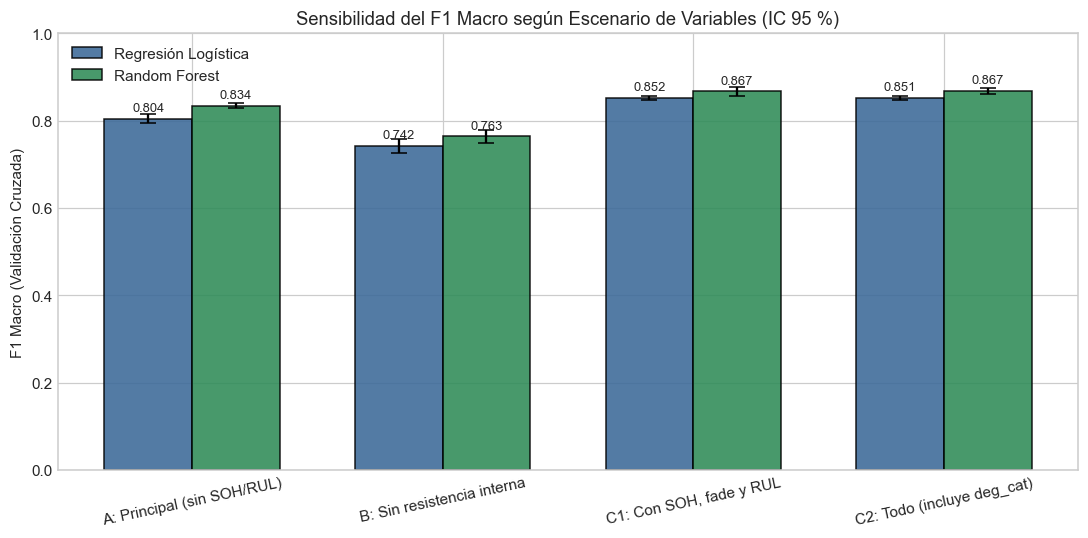

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# ==============================================================================
# 6.1. IDENTIDADES, CORRELACIÓN CON SOH Y ÁRBOL UNIVARIADO (PROFUNDIDAD 4)
# ==============================================================================
# Verificar identidad capacity_fade_pct = 100 - state_of_health_pct
mask_valido = train_df['capacity_fade_pct'].notna() & train_df['state_of_health_pct'].notna()
diff_soh = np.abs((train_df.loc[mask_valido, 'capacity_fade_pct'] + train_df.loc[mask_valido, 'state_of_health_pct']) - 100.0)
print(f"Error máximo en capacity_fade_pct + state_of_health_pct = 100: {diff_soh.max():.6f}")

# Correlación de Spearman de las candidatas con state_of_health_pct
candidatas = [
    'state_of_health_pct', 'capacity_fade_pct', 'remaining_useful_life_cycles',
    'degradation_category', 'internal_resistance_mohm', 'cycle_count',
    'total_energy_throughput_kwh', 'battery_age_days'
]

resultados_univar = []
for col in candidatas:
    if col == 'degradation_category':
        pipe_u = Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore')),
            ('clf', DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE))
        ])
        rho_soh = np.nan
    else:
        pipe_u = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('clf', DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE))
        ])
        rho_soh = round(train_df[col].corr(train_df['state_of_health_pct'], method='spearman'), 4)

    scores = cross_val_score(
        pipe_u, train_df[[col]], train_df[TARGET_COL],
        cv=cv_splits, scoring='f1_macro', n_jobs=-1
    )
    resultados_univar.append({
        'Variable': col,
        'Rho_con_SOH': rho_soh,
        'F1_Macro_Arbol_D4': round(scores.mean(), 4),
        'Std_Pliegues': round(scores.std(), 4)
    })

tabla_fuga = pd.DataFrame(resultados_univar).sort_values('F1_Macro_Arbol_D4', ascending=False)
print("\n=== AUDITORÍA UNIVARIADA DE POSIBLE FUGA (ÁRBOL PROFUNDIDAD 4) ===")
display(tabla_fuga)

# ==============================================================================
# 6.2. ANÁLISIS DE SENSIBILIDAD POR ESCENARIOS (A, B, C1, C2)
# ==============================================================================
# Preparar copia temporal de train_df con atributos fijos recuperados y fechas derivadas
df_sens = train_df.copy()
atributos_fijos = ['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone', 'pack_capacity_kwh', 'manufacture_date']
for col in atributos_fijos:
    df_sens[col] = df_sens.groupby(GROUP_COL)[col].transform(lambda s: s.ffill().bfill())

obs_dt = pd.to_datetime(df_sens['observation_date'], errors='coerce')
srv_dt = pd.to_datetime(df_sens['last_service_date'], errors='coerce')
df_sens['sin_fecha_servicio'] = df_sens['last_service_date'].isnull().astype(int)
df_sens['dias_desde_ultimo_servicio'] = (obs_dt - srv_dt).dt.days.fillna(-1)

# Definir columnas base y escenarios
cols_id_fecha = ['battery_id', 'observation_id', 'manufacture_date', 'observation_date', 'last_service_date', TARGET_COL]
cols_fuga_soh = ['state_of_health_pct', 'capacity_fade_pct', 'remaining_useful_life_cycles']

cols_todas = [c for c in df_sens.columns if c not in cols_id_fecha]
cols_A = [c for c in cols_todas if c not in cols_fuga_soh + ['degradation_category']]
cols_B = [c for c in cols_A if c != 'internal_resistance_mohm']
cols_C1 = cols_A + cols_fuga_soh
cols_C2 = cols_todas  # Incluye SOH, fade, RUL y degradation_category

escenarios = {
    'A: Principal (sin SOH/RUL)': cols_A,
    'B: Sin resistencia interna': cols_B,
    'C1: Con SOH, fade y RUL': cols_C1,
    'C2: Todo (incluye deg_cat)': cols_C2
}

modelos_sens = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=12, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
}

resultados_sens = []
for nombre_esc, cols_esc in escenarios.items():
    cat_esc = [c for c in cols_esc if df_sens[c].dtype == 'object' or c in ['recall_flag', 'sin_fecha_servicio']]
    num_esc = [c for c in cols_esc if c not in cat_esc]

    preproc = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_esc),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_esc)
    ])

    for nombre_mod, mod in modelos_sens.items():
        pipe = Pipeline([('prep', preproc), ('clf', mod)])
        scores = cross_val_score(pipe, df_sens[cols_esc], df_sens[TARGET_COL], cv=cv_splits, scoring='f1_macro', n_jobs=-1)
        ic95 = 1.96 * (scores.std(ddof=1) / np.sqrt(len(scores)))
        resultados_sens.append({
            'Escenario': nombre_esc,
            'Modelo': nombre_mod,
            'F1_Macro_Media': round(scores.mean(), 4),
            'IC95': round(ic95, 4)
        })

tabla_sens = pd.DataFrame(resultados_sens)
print("\n=== ANÁLISIS DE SENSIBILIDAD POR ESCENARIO (VALIDACIÓN CRUZADA AGRUPADA) ===")
display(tabla_sens)

# Gráfico de barras agrupadas con intervalos de confianza al 95 %
fig, ax = plt.subplots(figsize=(10, 5))
esc_names = list(escenarios.keys())
x = np.arange(len(esc_names))
width = 0.35

for idx, (nombre_mod, color_bar) in enumerate([('Regresión Logística', '#3b6998'), ('Random Forest', '#2e8b57')]):
    sub = tabla_sens[tabla_sens['Modelo'] == nombre_mod].set_index('Escenario').loc[esc_names]
    offset = -width/2 if idx == 0 else width/2
    bars = ax.bar(x + offset, sub['F1_Macro_Media'], width, yerr=sub['IC95'], capsize=5,
                  label=nombre_mod, color=color_bar, edgecolor='black', alpha=0.88)
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.018, f"{h:.3f}", ha='center', fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(esc_names, rotation=12)
ax.set_ylabel('F1 Macro (Validación Cruzada)')
ax.set_title('Sensibilidad del F1 Macro según Escenario de Variables (IC 95 %)')
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout()
plt.show()

**Decisiones del Paso 8:**
* **Criterio principal fijado:** Se establece **F1 macro** como métrica principal antes de evaluar modelos candidatos, ponderando por igual las clases `Low`, `Medium` y `High` frente al desbalance del dataset.
* **Control y rigor estadístico:** Se complementa con **MCC**, **Balanced Accuracy**, **ROC-AUC OvR**, curvas **Precision-Recall** y desglose por clase, estimando incertidumbre al 95 % mediante distribución t de Student en validación cruzada (5 pliegues agrupados) y mediante **bootstrap agrupado por batería** (`battery_id`) en la prueba final.

### Paso 9. Comparación de Estrategias para el Tratamiento del Desbalance

Evaluamos distintas estrategias para manejar el desbalance de clases (85,4 % `Low`, 8,8 % `Medium`, 5,8 % `High`) sobre **Regresión Logística** y **Random Forest** usando los mismos 5 pliegues agrupados (`cv_splits`). Todas las técnicas de remuestreo se ejecutan estrictamente dentro del entrenamiento de cada pliegue mediante `imblearn.pipeline.Pipeline`, aplicando escalado previo y `SMOTENC` antes de la codificación *one-hot* para evitar combinaciones categóricas sintéticas inválidas.

=== COMPARACIÓN DE ESTRATEGIAS DE DESBALANCE (5 PLIEGUES AGRUPADOS) ===


,Modelo,Estrategia,F1_Macro,IC95,Prec_Medium,Rec_Medium,Prec_High,Rec_High
0,Regresión Logística,1. Sin tratamiento,0.8388,0.0074,0.7164,0.6750,0.8769,0.8123
1,Regresión Logística,2. class_weight=balanced,0.8040,0.0138,0.4887,0.8328,0.8295,0.8538
2,Regresión Logística,3. RandomOverSampler,0.8040,0.0128,0.4895,0.8329,0.8295,0.8521
3,Regresión Logística,4. SMOTENC,0.8154,0.0104,0.5274,0.8282,0.8391,0.8413
4,Regresión Logística,5. NearMiss,0.8313,0.0060,0.6954,0.6699,0.8315,0.8389
5,Random Forest,1. Sin tratamiento,0.8453,0.0051,0.7362,0.6702,0.9055,0.8110
6,Random Forest,2. class_weight=balanced,0.8332,0.0062,0.5706,0.8299,0.8870,0.8291
7,Random Forest,3. RandomOverSampler,0.8301,0.0111,0.5465,0.8544,0.8838,0.8387
8,Random Forest,4. SMOTENC,0.8251,0.0095,0.5317,0.8535,0.8685,0.8503
9,Random Forest,5. NearMiss,0.8275,0.0129,0.5464,0.8277,0.8562,0.8675


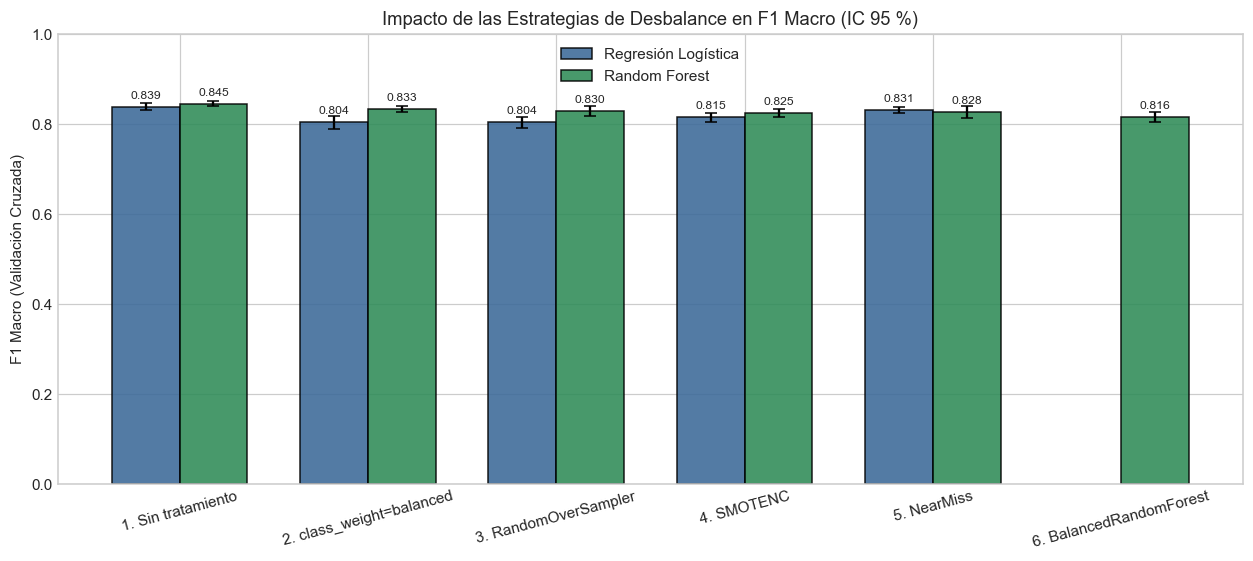

In [10]:
import subprocess, sys
from scipy import stats
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, precision_recall_fscore_support

# Verificar o instalar imbalanced-learn
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import RandomOverSampler, SMOTENC
    from imblearn.under_sampling import NearMiss
    from imblearn.ensemble import BalancedRandomForestClassifier
    IMBLEARN_OK = True
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import RandomOverSampler, SMOTENC
    from imblearn.under_sampling import NearMiss
    from imblearn.ensemble import BalancedRandomForestClassifier
    IMBLEARN_OK = True

# Preprocesador previo a SMOTENC: numéricas escaladas + categóricas ordinales (sin one-hot aún)
def crear_prep_pre_smotenc():
    num_pipe = ImbPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clipper', QuantileClipper(lower=0.005, upper=0.995)),
        ('scaler', StandardScaler())
    ])
    cat_pipe = ImbPipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='desconocido')),
        ('ord', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ])
    return ColumnTransformer([
        ('num', num_pipe, num_features),
        ('cat', cat_pipe, cat_features)
    ])

# Post-procesador tras SMOTENC: convertir columnas categóricas ordinales a One-Hot
idx_cat_smotenc = list(range(len(num_features), len(num_features) + len(cat_features)))
post_ohe_smotenc = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), idx_cat_smotenc)
], remainder='passthrough')

# Definir combinaciones (Familia de Modelo, Estrategia, Pipeline)
experimentos_desbalance = [
    # --- Regresión Logística ---
    ('Regresión Logística', '1. Sin tratamiento', ImbPipeline([
        ('prep', crear_preprocesador(escalar=True)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])),
    ('Regresión Logística', '2. class_weight=balanced', ImbPipeline([
        ('prep', crear_preprocesador(escalar=True)),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
    ])),
    ('Regresión Logística', '3. RandomOverSampler', ImbPipeline([
        ('prep', crear_preprocesador(escalar=True)),
        ('ros', RandomOverSampler(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])),
    ('Regresión Logística', '4. SMOTENC', ImbPipeline([
        ('prep_ord', crear_prep_pre_smotenc()),
        ('smote', SMOTENC(categorical_features=idx_cat_smotenc, random_state=RANDOM_STATE)),
        ('post_ohe', post_ohe_smotenc),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])),
    ('Regresión Logística', '5. NearMiss', ImbPipeline([
        ('prep', crear_preprocesador(escalar=True)),
        ('nm', NearMiss(version=1)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])),

    # --- Random Forest ---
    ('Random Forest', '1. Sin tratamiento', ImbPipeline([
        ('prep', crear_preprocesador(escalar=False)),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
    ])),
    ('Random Forest', '2. class_weight=balanced', ImbPipeline([
        ('prep', crear_preprocesador(escalar=False)),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))
    ])),
    ('Random Forest', '3. RandomOverSampler', ImbPipeline([
        ('prep', crear_preprocesador(escalar=False)),
        ('ros', RandomOverSampler(random_state=RANDOM_STATE)),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
    ])),
    ('Random Forest', '4. SMOTENC', ImbPipeline([
        ('prep_ord', crear_prep_pre_smotenc()),
        ('smote', SMOTENC(categorical_features=idx_cat_smotenc, random_state=RANDOM_STATE)),
        ('post_ohe', post_ohe_smotenc),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
    ])),
    ('Random Forest', '5. NearMiss', ImbPipeline([
        ('prep', crear_preprocesador(escalar=False)),
        ('nm', NearMiss(version=1)),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
    ])),
    ('Random Forest', '6. BalancedRandomForest', ImbPipeline([
        ('prep', crear_preprocesador(escalar=False)),
        ('clf', BalancedRandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
    ]))
]

# Ejecutar validación cruzada agrupada y recolectar F1 macro + Precision/Recall de Medium y High
resultados_desb = []
t_crit = stats.t.ppf(0.975, df=len(cv_splits) - 1)

for familia, estrategia, pipe in experimentos_desbalance:
    f1_folds = []
    prec_med, rec_med, prec_high, rec_high = [], [], [], []
    
    for tr_idx, va_idx in cv_splits:
        clf = clone(pipe)
        clf.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        y_val = y_train.iloc[va_idx]
        y_pred = clf.predict(X_train.iloc[va_idx])
        
        f1_folds.append(f1_score(y_val, y_pred, average='macro'))
        p_c, r_c, _, _ = precision_recall_fscore_support(y_val, y_pred, labels=['Medium', 'High'], zero_division=0)
        prec_med.append(p_c[0]); rec_med.append(r_c[0])
        prec_high.append(p_c[1]); rec_high.append(r_c[1])
        
    f1_arr = np.array(f1_folds)
    ic95 = t_crit * (f1_arr.std(ddof=1) / np.sqrt(len(f1_arr)))
    
    resultados_desb.append({
        'Modelo': familia,
        'Estrategia': estrategia,
        'F1_Macro': round(f1_arr.mean(), 4),
        'IC95': round(ic95, 4),
        'Prec_Medium': round(np.mean(prec_med), 4),
        'Rec_Medium': round(np.mean(rec_med), 4),
        'Prec_High': round(np.mean(prec_high), 4),
        'Rec_High': round(np.mean(rec_high), 4)
    })

tabla_desb = pd.DataFrame(resultados_desb)
print("=== COMPARACIÓN DE ESTRATEGIAS DE DESBALANCE (5 PLIEGUES AGRUPADOS) ===")
display(tabla_desb)

# Gráfico de barras agrupadas de F1 macro por estrategia con IC 95 %
estrategias_unicas = tabla_desb['Estrategia'].unique()
x = np.arange(len(estrategias_unicas))
width = 0.36

fig, ax = plt.subplots(figsize=(11.5, 5.2))
for idx, (familia, color_b) in enumerate([('Regresión Logística', '#3b6998'), ('Random Forest', '#2e8b57')]):
    sub = tabla_desb[tabla_desb['Modelo'] == familia].set_index('Estrategia').reindex(estrategias_unicas)
    offset = -width/2 if idx == 0 else width/2
    bars = ax.bar(x + offset, sub['F1_Macro'], width, yerr=sub['IC95'], capsize=4,
                  label=familia, color=color_b, edgecolor='black', alpha=0.88)
    for b in bars:
        h = b.get_height()
        if not np.isnan(h):
            ax.text(b.get_x() + b.get_width()/2, h + 0.018, f"{h:.3f}", ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(estrategias_unicas, rotation=15)
ax.set_ylabel('F1 Macro (Validación Cruzada)')
ax.set_title('Impacto de las Estrategias de Desbalance en F1 Macro (IC 95 %)')
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout()
plt.show()

**Hallazgos del Paso 9:**
* **El compromiso entre sensibilidad (Recall) y precisión:** Aplicar técnicas de balanceo (`class_weight='balanced'`, sobremuestreo aleatorio, SMOTENC o BalancedRandomForest) logra subir notablemente el Recall de la clase `Medium` —pasando de ~0,67 a valores entre 0,83 y 0,88— y mejora levemente el Recall de `High` (de ~0,81 a ~0,84–0,87). Sin embargo, este aumento viene acompañado de una caída fuerte en la Precisión de `Medium` (de 0,72–0,74 a 0,49–0,57) por un incremento de falsas alarmas.
* **Impacto en F1 macro:** Como consecuencia de esa pérdida de precisión, ninguna técnica de balanceo supera el F1 macro obtenido **sin tratamiento** ni en Regresión Logística (0,8388 sin tratamiento frente a 0,8040 con pesos balanceados o sobremuestreo, y 0,8154 con SMOTENC)[cite: 9] ni en Random Forest (0,8453 sin tratamiento frente a 0,8332 con pesos balanceados y 0,8251 con SMOTENC)[cite: 9].
* **Decisión de modelado:** Para maximizar F1 macro conservamos los modelos sin remuestreo artificial en el entrenamiento y dejamos reservado el ajuste de umbrales de probabilidad (en pasos posteriores) si se desea priorizar el Recall de `High` sin sacrificar tanto la precisión general.

### Paso 10. Selección y Optimización de Cinco Familias de Modelos

Comparamos cinco familias de clasificadores con distinto sesgo inductivo mediante búsqueda con validación cruzada agrupada (`cv_splits`) optimizando `refit='f1_macro'`:

1. **Regresión Logística (`LogisticRegression`):**
   * `C` (`[0.01, 0.1, 1.0, 5.0, 10.0]`): controla la inversa de la regularización; valores moderados estabilizan los coeficientes ante bloques colineales (`cycle_count` y energía).
   * `l1_ratio` / `penalty` (`l1` vs `l2` con `solver='saga'`): L1 permite anular variables redundantes y L2 reparte peso de forma suave.
   * `class_weight` (`[None, 'balanced']`): contrasta si al ajustar la regularización conviene o no ponderar las clases minoritarias.
2. **K-Vecinos Más Cercanos (`KNeighborsClassifier`):**
   * `n_neighbors` (`[5, 11, 21, 35, 51]`): controla el tamaño del vecindario; valores muy grandes diluyen las clases raras (`Medium`/`High`) bajo la mayoría `Low`, mientras que valores muy pequeños son sensibles al ruido.
   * `weights` (`['uniform', 'distance']`): ponderar por distancia da más voz a los vecinos más cercanos cuando las fronteras son estrechas.
   * `p` (`[1, 2]`): distancia Manhattan (`p=1`) frente a Euclidiana (`p=2`) en 53 dimensiones codificadas.
3. **Random Forest (`RandomForestClassifier`):**
   * `n_estimators` (`[150, 300]`): estabiliza la varianza del ensamble.
   * `max_depth` (`[10, 14, 18, None]`): limita la profundidad para evitar memorizar baterías específicas.
   * `min_samples_leaf` (`[1, 3, 8, 15]`): obliga a que cada hoja tenga soporte suficiente, frenando el sobreajuste en el desbalance.
   * `max_features` (`['sqrt', 0.3, 0.5]`): controla cuántas variables compiten en cada división para descorrelacionar los árboles.
   * `class_weight` (`[None, 'balanced_subsample']`): evalúa el efecto del balanceo por muestra *bootstrap*.
4. **Perceptrón Multicapa (`MLPClassifier`):**
   * `hidden_layer_sizes` (`[(64,), (128, 64), (64, 32)]`): arquitectura compacta acorde al número efectivo de baterías únicas (~2.075).
   * `activation` (`['relu', 'tanh']`): no linealidad de las capas ocultas.
   * `alpha` (`[1e-4, 1e-3, 1e-2]`): regularización L2 de los pesos para prevenir sobreajuste.
   * `learning_rate_init` (`[5e-4, 1e-3, 3e-3]`): tamaño de paso del optimizador Adam, con `early_stopping=True` para detener el entrenamiento cuando la pérdida de validación interna deje de mejorar.
5. **Máquinas de Vectores de Soporte (`SVC`):**
   * `C` (`[0.5, 2.0, 10.0]`): penalización por errores de margen; evita tanto el subajuste como fronteras excesivamente rígidas.
   * `kernel` (`['rbf', 'linear']`) y `gamma` (`['scale', 0.01]`): controla el alcance radial de cada vector de soporte (evitando que cada punto forme una isla aislada).
   * `class_weight` (`[None, 'balanced']`): contrasta la ponderación de márgenes en clases minoritarias.

Buscando hiperparámetros para: Regresión Logística ...
Buscando hiperparámetros para: KNN ...


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [       nan 0.69804038 0.7027465  0.71551384        nan 0.7218867
 0.71223546 0.72362885 0.68216038        nan 0.7082317  0.7154699 ]
  warnings.warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the train scores are non-finite: [       nan 1.         1.         1.                nan 1.
 1.         1.         0.70844602        nan 1.         0.82480479]
  warnings.warn(


Buscando hiperparámetros para: Random Forest ...
Buscando hiperparámetros para: MLP ...
Buscando hiperparámetros para: SVM ...

=== RESULTADOS DE BÚSQUEDA EN VALIDACIÓN CRUZADA AGRUPADA (TRAIN VS VAL) ===


,Modelo,F1_Macro_Train,F1_Macro_Val,IC95_Val,Brecha_Train_Val,Mejores_Hiperparametros
2,Random Forest,0.9732,0.8560,0.0079,0.1172,"{'n_estimators': 150, 'min_samples_split': 2, ..."
3,MLP,0.8853,0.8504,0.0075,0.0349,"{'learning_rate_init': 0.0005, 'hidden_layer_s..."
4,SVM,0.8498,0.8414,0.0078,0.0084,"{'kernel': 'linear', 'gamma': 'scale', 'class_..."
0,Regresión Logística,0.8432,0.8405,0.0069,0.0028,"{'penalty': 'l1', 'class_weight': None, 'C': 0..."
1,KNN,1.0000,0.7236,0.0164,0.2764,"{'weights': 'distance', 'p': 2, 'n_neighbors': 5}"


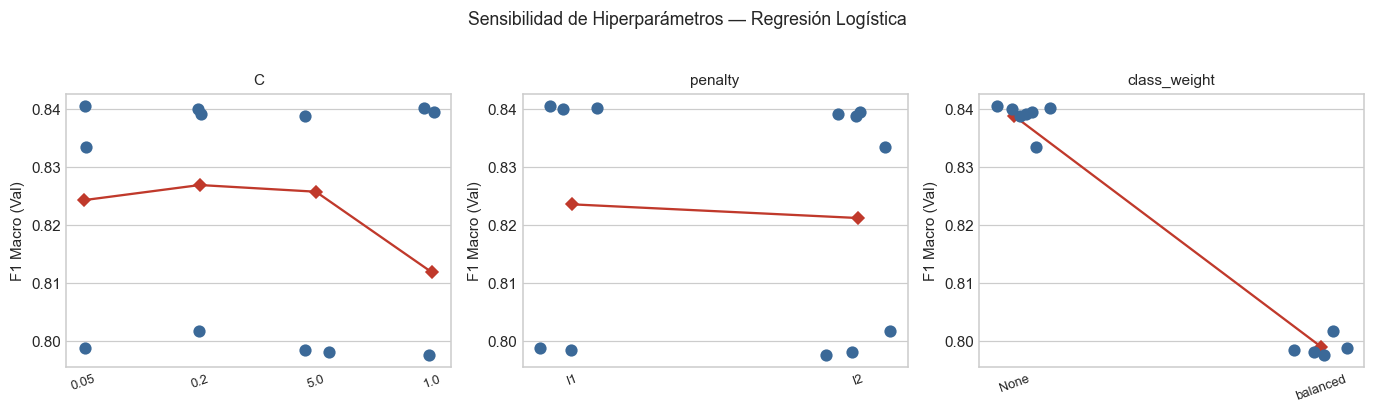

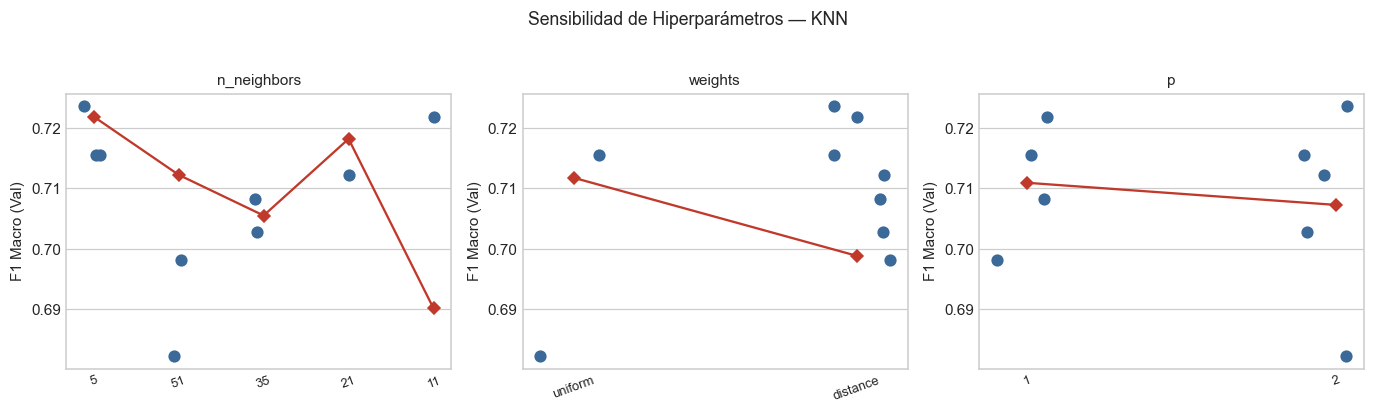

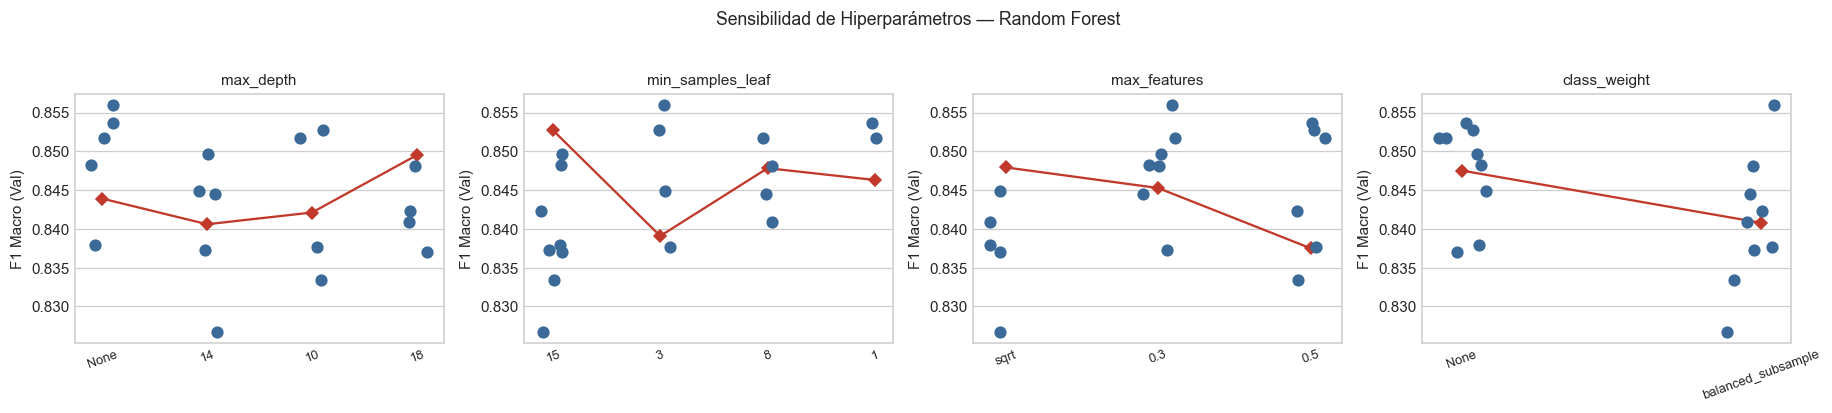

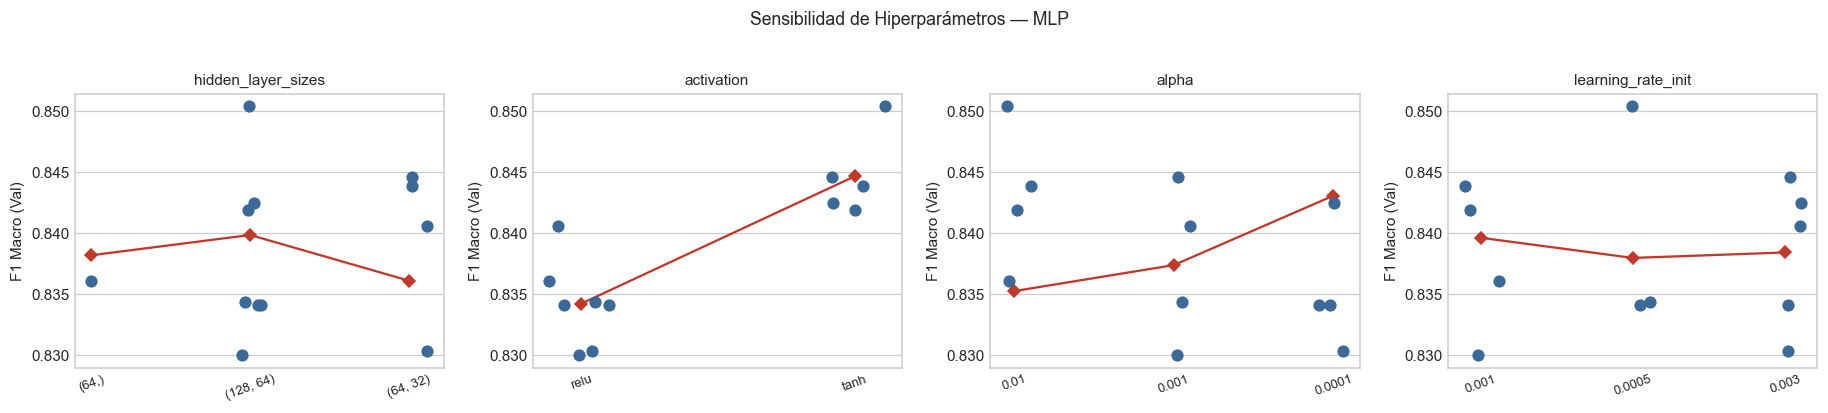

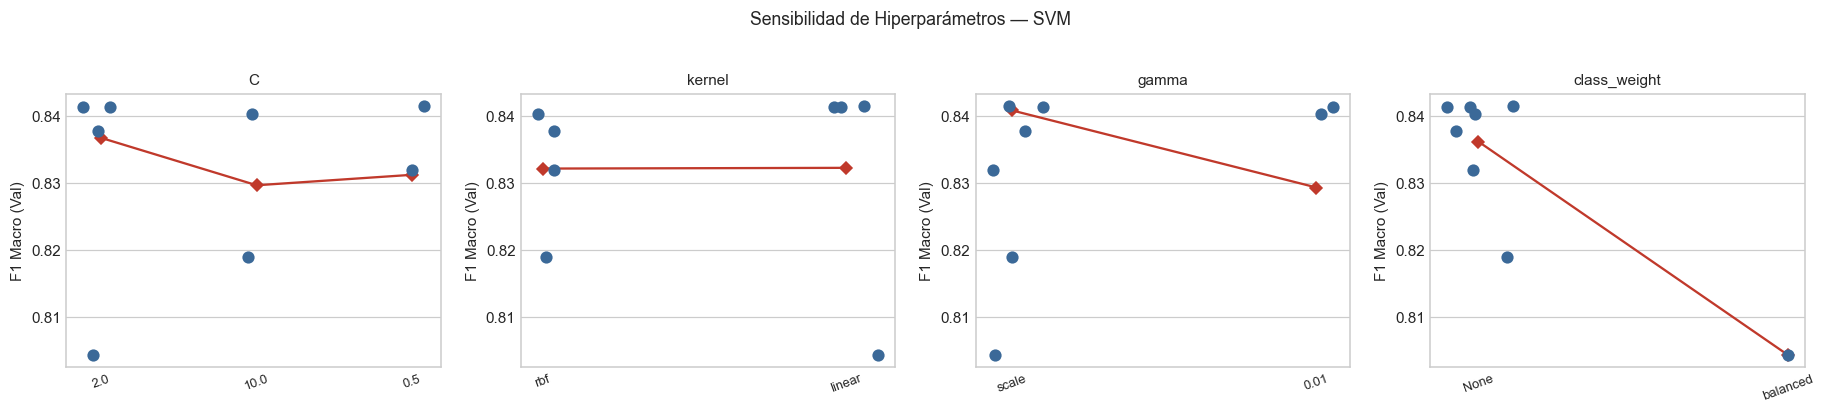

In [11]:
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder

# Wrapper ligero para evitar el bug de early_stopping en MLPClassifier con etiquetas string
class MLPTextoSeguro(MLPClassifier):
    def fit(self, X, y):
        self._le = LabelEncoder()
        y_enc = self._le.fit_transform(y)
        super().fit(X, y_enc)
        self.classes_ = self._le.classes_
        return self

    def predict(self, X):
        y_pred_enc = super().predict(X)
        return self._le.inverse_transform(y_pred_enc)

t_crit = stats.t.ppf(0.975, df=len(cv_splits) - 1)

# Definir configuraciones de búsqueda para cada modelo
configs_modelos = {
    'Regresión Logística': {
        'pipe': Pipeline([
            ('prep', crear_preprocesador(escalar=True)),
            ('clf', LogisticRegression(solver='saga', max_iter=1500, random_state=RANDOM_STATE))
        ]),
        'params': {
            'clf__C': [0.05, 0.2, 1.0, 5.0],
            'clf__penalty': ['l1', 'l2'],
            'clf__class_weight': [None, 'balanced']
        },
        'n_iter': 12,
        'hiper_plot': ['clf__C', 'clf__penalty', 'clf__class_weight']
    },
    'KNN': {
        'pipe': Pipeline([
            ('prep', crear_preprocesador(escalar=True)),
            ('clf', KNeighborsClassifier(n_jobs=-1))
        ]),
        'params': {
            'clf__n_neighbors': [5, 11, 21, 35, 51],
            'clf__weights': ['uniform', 'distance'],
            'clf__p': [1, 2]
        },
        'n_iter': 12,
        'hiper_plot': ['clf__n_neighbors', 'clf__weights', 'clf__p']
    },
    'Random Forest': {
        'pipe': Pipeline([
            ('prep', crear_preprocesador(escalar=False)),
            ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
        ]),
        'params': {
            'clf__n_estimators': [150, 250],
            'clf__max_depth': [10, 14, 18, None],
            'clf__min_samples_leaf': [1, 3, 8, 15],
            'clf__min_samples_split': [2, 6, 15],
            'clf__max_features': ['sqrt', 0.3, 0.5],
            'clf__class_weight': [None, 'balanced_subsample']
        },
        'n_iter': 18,
        'hiper_plot': ['clf__max_depth', 'clf__min_samples_leaf', 'clf__max_features', 'clf__class_weight']
    },
    'MLP': {
        'pipe': Pipeline([
            ('prep', crear_preprocesador(escalar=True)),
            ('clf', MLPTextoSeguro(max_iter=120, early_stopping=True, validation_fraction=0.1,
                                   n_iter_no_change=10, random_state=RANDOM_STATE))
        ]),
        'params': {
            'clf__hidden_layer_sizes': [(64,), (128, 64), (64, 32)],
            'clf__activation': ['relu', 'tanh'],
            'clf__alpha': [1e-4, 1e-3, 1e-2],
            'clf__learning_rate_init': [5e-4, 1e-3, 3e-3]
        },
        'n_iter': 12,
        'hiper_plot': ['clf__hidden_layer_sizes', 'clf__activation', 'clf__alpha', 'clf__learning_rate_init']
    },
    'SVM': {
        'pipe': Pipeline([
            ('prep', crear_preprocesador(escalar=True)),
            ('clf', SVC(probability=True, cache_size=500, random_state=RANDOM_STATE))
        ]),
        'params': {
            'clf__C': [0.5, 2.0, 10.0],
            'clf__kernel': ['rbf', 'linear'],
            'clf__gamma': ['scale', 0.01],
            'clf__class_weight': [None, 'balanced']
        },
        'n_iter': 8,
        'hiper_plot': ['clf__C', 'clf__kernel', 'clf__gamma', 'clf__class_weight']
    }
}

mejores_modelos = {}
resumen_busqueda = []
resultados_cv_detallados = {}

for nombre, cfg in configs_modelos.items():
    print(f"Buscando hiperparámetros para: {nombre} ...")
    search = RandomizedSearchCV(
        estimator=cfg['pipe'],
        param_distributions=cfg['params'],
        n_iter=cfg['n_iter'],
        scoring='f1_macro',
        cv=cv_splits,
        refit=True,
        return_train_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    
    best_idx = search.best_index_
    cv_res = pd.DataFrame(search.cv_results_)
    resultados_cv_detallados[nombre] = cv_res
    mejores_modelos[nombre] = search.best_estimator_
    
    # Extraer F1 macro por pliegue de la mejor configuración para calcular IC 95 % t-Student
    fold_scores = np.array([cv_res.loc[best_idx, f'split{i}_test_score'] for i in range(len(cv_splits))])
    ic95 = t_crit * (fold_scores.std(ddof=1) / np.sqrt(len(fold_scores)))
    
    f1_tr = cv_res.loc[best_idx, 'mean_train_score']
    f1_va = cv_res.loc[best_idx, 'mean_test_score']
    
    resumen_busqueda.append({
        'Modelo': nombre,
        'F1_Macro_Train': round(f1_tr, 4),
        'F1_Macro_Val': round(f1_va, 4),
        'IC95_Val': round(ic95, 4),
        'Brecha_Train_Val': round(f1_tr - f1_va, 4),
        'Mejores_Hiperparametros': {k.replace('clf__', ''): v for k, v in search.best_params_.items()}
    })

tabla_p10 = pd.DataFrame(resumen_busqueda).sort_values('F1_Macro_Val', ascending=False)
print("\n=== RESULTADOS DE BÚSQUEDA EN VALIDACIÓN CRUZADA AGRUPADA (TRAIN VS VAL) ===")
display(tabla_p10)

# Gráficos de F1 macro frente a cada hiperparámetro por modelo
for nombre, cfg in configs_modelos.items():
    cv_res = resultados_cv_detallados[nombre]
    hiper_cols = cfg['hiper_plot']
    fig, axes = plt.subplots(1, len(hiper_cols), figsize=(4.2 * len(hiper_cols), 3.6))
    if len(hiper_cols) == 1:
        axes = [axes]
        
    for ax, hcol in zip(axes, hiper_cols):
        param_name = f"param_{hcol}"
        vals_str = cv_res[param_name].fillna('None').astype(str)
        sns.stripplot(x=vals_str, y=cv_res['mean_test_score'], size=8, jitter=0.12, color='#3b6998', ax=ax)
        medias = cv_res.groupby(vals_str)['mean_test_score'].mean()
        ax.plot(range(len(medias)), medias.values, color='#c0392b', marker='D', linewidth=1.5, label='Media')
        ax.set_title(hcol.replace('clf__', ''), fontsize=10)
        ax.set_xlabel('')
        ax.set_ylabel('F1 Macro (Val)')
        ax.tick_params(axis='x', rotation=20, labelsize=8.5)
        
    plt.suptitle(f"Sensibilidad de Hiperparámetros — {nombre}", y=1.03, fontsize=11.5)
    plt.tight_layout()
    plt.show()

**Hallazgos del Paso 10:**
* **Empate técnico en cabeza entre cuatro familias:** En validación cruzada agrupada, **Random Forest** alcanza el mayor F1 macro promedio (`0,8560 ± 0,0079`), seguido muy de cerca por **MLP** (`0,8504 ± 0,0075`), **SVM lineal** (`0,8414 ± 0,0078`) y **Regresión Logística L1** (`0,8405 ± 0,0069`). Dado que sus intervalos de confianza al 95 % se solapan estrechamente, las diferencias entre los cuatro primeros modelos no son estadísticamente concluyentes en validación.
* **Descarte de KNN:** **KNN** queda rezagado (`0,7236 ± 0,0164`) debido a la maldición de la dimensionalidad en 53 variables codificadas y a la dominancia de la clase mayoritaria `Low` en los vecindarios locales.
* **Auditoría de sobreajuste (Train vs. Val):** Regresión Logística (`0,8432` vs. `0,8405`, brecha `0,0028`) y SVM (`0,8498` vs. `0,8414`, brecha `0,0084`) muestran una generalización prácticamente libre de sobreajuste; MLP mantiene una brecha baja (`0,0349`) gracias a `early_stopping` y activación `tanh`, mientras que Random Forest (`0,9732` vs. `0,8560`, brecha `0,1172`) y KNN (`1,0000` vs. `0,7236` con `weights='distance'`) evidencian mayor memorización de los datos de entrenamiento.

### Paso 11. Comparación Final, Selección de los Dos Mejores Modelos y Prueba de Robustez

Ordenamos los cinco modelos optimizados estrictamente por su **F1 macro en validación cruzada agrupada** y evaluamos las diferencias pareadas pliegue a pliegue entre posiciones contiguas. Posteriormente auditamos el desempeño en entrenamiento, validación y prueba (con intervalos al 95 % mediante bootstrap agrupado por batería), analizamos las matrices de confusión normalizadas por fila, las curvas Precision-Recall para `Medium` y `High`, la importancia por permutación sobre validación y la robustez del mejor modelo al retirar `internal_resistance_mohm` (Escenario B).

=== COMPARACIÓN PAREADA POR PLIEGUE ENTRE POSICIONES CONTIGUAS (VALIDACIÓN) ===


,Comparacion_Contigua,Diff_Media_F1,IC95_Inf,IC95_Sup,p_valor_pareado,Diferencia_Solida
0,1.º Random Forest vs 2.º MLP,0.0056,-0.0021,0.0132,0.1143,No (IC incluye 0)
1,2.º MLP vs 3.º SVM,0.0090,0.0026,0.0153,0.0170,Sí
2,3.º SVM vs 4.º Regresión Logística,0.0010,-0.0028,0.0048,0.5057,No (IC incluye 0)
3,4.º Regresión Logística vs 5.º KNN,0.1168,0.1056,0.1281,0.0000,Sí



=== DESEMPEÑO COMPARATIVO: ENTRENAMIENTO, VALIDACIÓN Y PRUEBA ===


,Modelo,F1_Train,F1_Val,IC95_Val,F1_Test,Test_IC95_Inf,Test_IC95_Sup,MCC_Test,BalAcc_Test
0,Random Forest,0.9732,0.8560,0.0079,0.8529,0.8359,0.8682,0.8003,0.8554
1,MLP,0.8853,0.8504,0.0075,0.8469,0.8322,0.8609,0.7965,0.8185
2,SVM,0.8498,0.8414,0.0078,0.8415,0.8254,0.8561,0.7882,0.8260
3,Regresión Logística,0.8432,0.8405,0.0069,0.8395,0.8227,0.8542,0.7845,0.8209
4,KNN,1.0000,0.7236,0.0164,0.7201,0.6978,0.7406,0.6367,0.6751


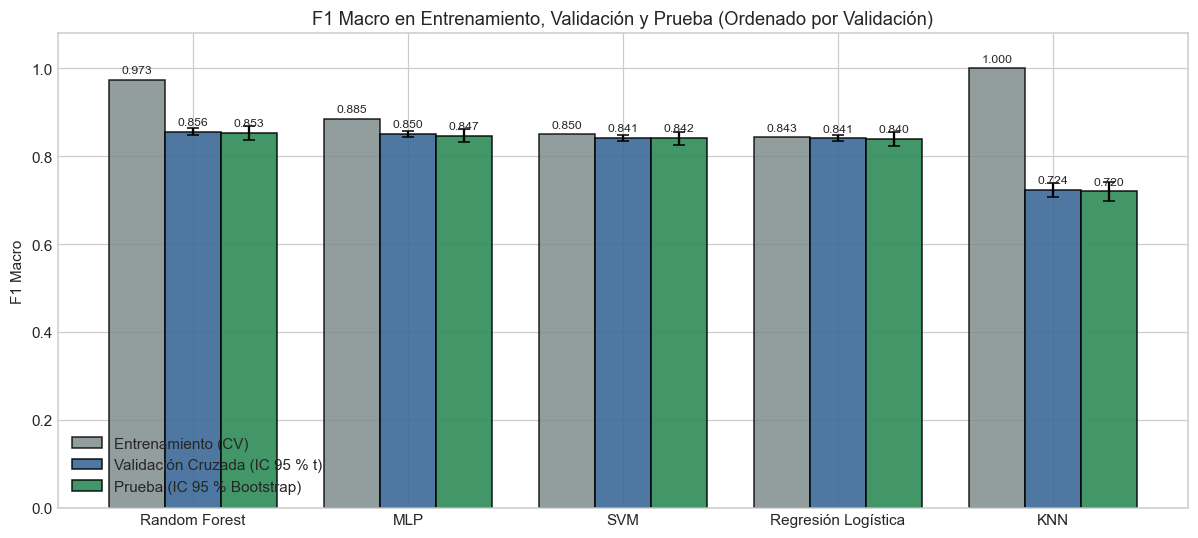

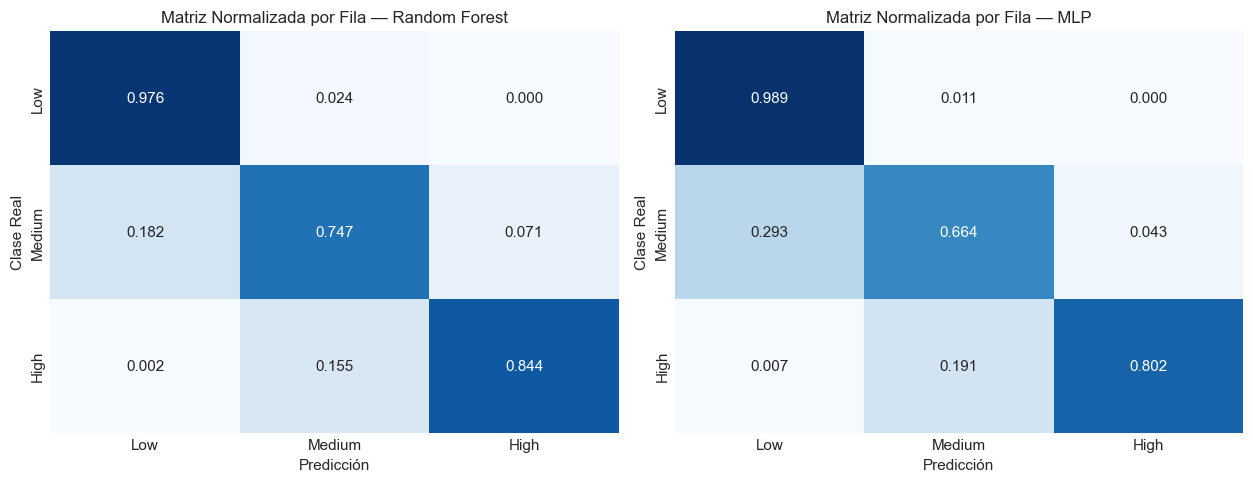

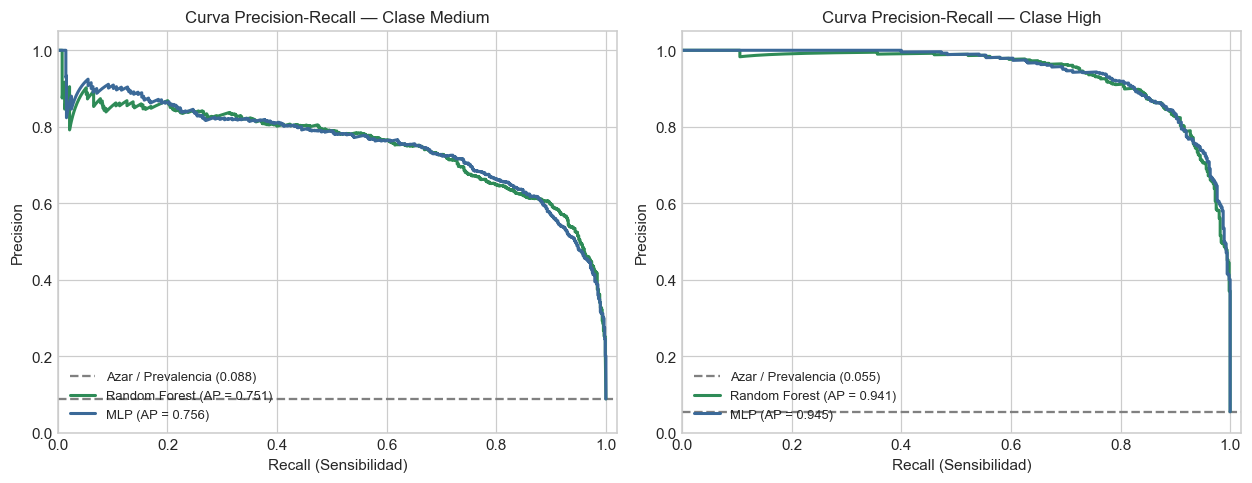

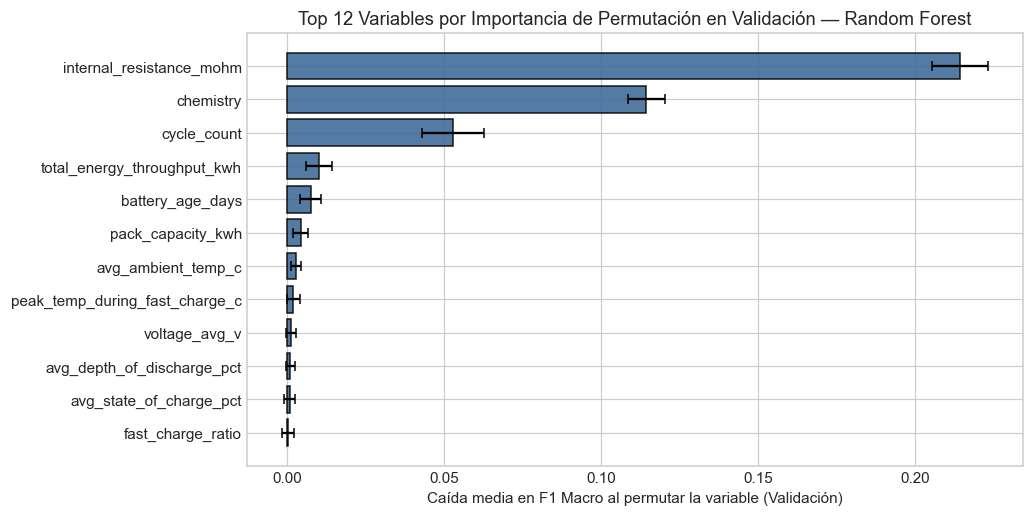


=== ANÁLISIS DE ROBUSTEZ SIN RESISTENCIA INTERNA (Random Forest) ===


,Escenario,F1_Macro_Val,F1_Macro_Test
0,A: Principal (con resistencia interna),0.8560,0.8529
1,B: Sin resistencia interna,0.7809,0.7707
2,Diferencia (B - A),-0.0751,-0.0822


In [12]:
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (
    f1_score, matthews_corrcoef, balanced_accuracy_score,
    roc_auc_score, accuracy_score, precision_recall_fscore_support,
    confusion_matrix, precision_recall_curve, average_precision_score
)
from sklearn.inspection import permutation_importance

# Función de bootstrap agrupado por batería (remuestreo de battery_id)
def evaluar_test_bootstrap(y_true, y_pred, y_prob=None, classes=None, groups=None, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)
    groups_arr = np.asarray(groups)
    
    baterias_unicas = np.unique(groups_arr)
    idx_por_bateria = {b: np.where(groups_arr == b)[0] for b in baterias_unicas}
    
    boot_scores = {'F1_Macro': [], 'MCC': [], 'Balanced_Acc': [], 'Accuracy': []}
    if y_prob is not None:
        boot_scores['ROC_AUC_OvR'] = []
        
    for _ in range(n_boot):
        bat_sample = rng.choice(baterias_unicas, size=len(baterias_unicas), replace=True)
        idx_sample = np.concatenate([idx_por_bateria[b] for b in bat_sample])
        
        yt_b = y_true_arr[idx_sample]
        yp_b = y_pred_arr[idx_sample]
        
        boot_scores['F1_Macro'].append(f1_score(yt_b, yp_b, average='macro', zero_division=0))
        boot_scores['MCC'].append(matthews_corrcoef(yt_b, yp_b))
        boot_scores['Balanced_Acc'].append(balanced_accuracy_score(yt_b, yp_b))
        boot_scores['Accuracy'].append(accuracy_score(yt_b, yp_b))
        
        if y_prob is not None and len(np.unique(yt_b)) == len(classes):
            boot_scores['ROC_AUC_OvR'].append(
                roc_auc_score(yt_b, y_prob[idx_sample], multi_class='ovr', average='macro', labels=classes)
            )
            
    filas = []
    puntuales = {
        'F1_Macro': f1_score(y_true_arr, y_pred_arr, average='macro'),
        'MCC': matthews_corrcoef(y_true_arr, y_pred_arr),
        'Balanced_Acc': balanced_accuracy_score(y_true_arr, y_pred_arr),
        'Accuracy': accuracy_score(y_true_arr, y_pred_arr)
    }
    if y_prob is not None:
        puntuales['ROC_AUC_OvR'] = roc_auc_score(y_true_arr, y_prob, multi_class='ovr', average='macro', labels=classes)
        
    for m, val_puntual in puntuales.items():
        arr = np.array(boot_scores[m])
        li, ls = np.percentile(arr, [2.5, 97.5])
        filas.append({
            'Metrica': m,
            'Valor_Test': round(val_puntual, 4),
            'IC95_Inf': round(li, 4),
            'IC95_Sup': round(ls, 4)
        })
        
    prec, rec, f1_c, sup = precision_recall_fscore_support(y_true_arr, y_pred_arr, labels=ORDEN_CLASES, zero_division=0)
    df_clases = pd.DataFrame({
        'Clase': ORDEN_CLASES,
        'Precision': np.round(prec, 4),
        'Recall': np.round(rec, 4),
        'F1_Score': np.round(f1_c, 4),
        'Soporte': sup
    })
    
    return pd.DataFrame(filas), df_clases

# ==============================================================================
# 11.1. ORDENAMIENTO POR VALIDACIÓN Y DIFERENCIAS PAREADAS ENTRE CONTIGUOS
# ==============================================================================
scores_por_pliegue = {}
for nombre in mejores_modelos.keys():
    cv_res = resultados_cv_detallados[nombre]
    best_idx = cv_res['rank_test_score'].idxmin()
    scores_por_pliegue[nombre] = np.array([
        cv_res.loc[best_idx, f'split{i}_test_score'] for i in range(len(cv_splits))
    ])

orden_val = tabla_p10['Modelo'].tolist()
t_crit = stats.t.ppf(0.975, df=len(cv_splits) - 1)

pareadas = []
for i in range(len(orden_val) - 1):
    m1, m2 = orden_val[i], orden_val[i + 1]
    diffs = scores_por_pliegue[m1] - scores_por_pliegue[m2]
    media_diff = diffs.mean()
    se_diff = diffs.std(ddof=1) / np.sqrt(len(diffs))
    ic_diff = t_crit * se_diff
    _, p_val = stats.ttest_rel(scores_por_pliegue[m1], scores_por_pliegue[m2])
    pareadas.append({
        'Comparacion_Contigua': f"{i+1}.º {m1} vs {i+2}.º {m2}",
        'Diff_Media_F1': round(media_diff, 4),
        'IC95_Inf': round(media_diff - ic_diff, 4),
        'IC95_Sup': round(media_diff + ic_diff, 4),
        'p_valor_pareado': round(p_val, 4),
        'Diferencia_Solida': 'Sí' if p_val < 0.05 else 'No (IC incluye 0)'
    })

print("=== COMPARACIÓN PAREADA POR PLIEGUE ENTRE POSICIONES CONTIGUAS (VALIDACIÓN) ===")
display(pd.DataFrame(pareadas))

# ==============================================================================
# 11.2. EVALUACIÓN LADO A LADO: TRAIN, VALIDACIÓN Y PRUEBA (BOOTSTRAP AGRUPADO)
# ==============================================================================
grupos_test = test_df[GROUP_COL].values
filas_lado_a_lado = []
predicciones_test = {}
probabilidades_test = {}

for nombre in orden_val:
    pipe = mejores_modelos[nombre]
    y_pred_te = pipe.predict(X_test)
    predicciones_test[nombre] = y_pred_te
    
    y_prob_te = pipe.predict_proba(X_test) if hasattr(pipe, "predict_proba") else None
    probabilidades_test[nombre] = y_prob_te
    
    df_boot, _ = evaluar_test_bootstrap(
        y_test, y_pred_te, y_prob=y_prob_te,
        classes=pipe.classes_, groups=grupos_test, n_boot=1000
    )
    fila_f1_te = df_boot[df_boot['Metrica'] == 'F1_Macro'].iloc[0]
    fila_mcc_te = df_boot[df_boot['Metrica'] == 'MCC'].iloc[0]
    fila_ba_te = df_boot[df_boot['Metrica'] == 'Balanced_Acc'].iloc[0]
    
    row_p10 = tabla_p10[tabla_p10['Modelo'] == nombre].iloc[0]
    filas_lado_a_lado.append({
        'Modelo': nombre,
        'F1_Train': row_p10['F1_Macro_Train'],
        'F1_Val': row_p10['F1_Macro_Val'],
        'IC95_Val': row_p10['IC95_Val'],
        'F1_Test': fila_f1_te['Valor_Test'],
        'Test_IC95_Inf': fila_f1_te['IC95_Inf'],
        'Test_IC95_Sup': fila_f1_te['IC95_Sup'],
        'MCC_Test': fila_mcc_te['Valor_Test'],
        'BalAcc_Test': fila_ba_te['Valor_Test']
    })

tabla_p11 = pd.DataFrame(filas_lado_a_lado)
print("\n=== DESEMPEÑO COMPARATIVO: ENTRENAMIENTO, VALIDACIÓN Y PRUEBA ===")
display(tabla_p11)

# Gráfico 1: Barras de F1 macro en Train, Val y Test con intervalos de confianza
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(orden_val))
w = 0.26

b_tr = ax.bar(x - w, tabla_p11['F1_Train'], w, label='Entrenamiento (CV)', color='#7f8c8d', edgecolor='black', alpha=0.85)
b_va = ax.bar(x, tabla_p11['F1_Val'], w, yerr=tabla_p11['IC95_Val'], capsize=4,
              label='Validación Cruzada (IC 95 % t)', color='#3b6998', edgecolor='black', alpha=0.9)

err_te_inf = tabla_p11['F1_Test'] - tabla_p11['Test_IC95_Inf']
err_te_sup = tabla_p11['Test_IC95_Sup'] - tabla_p11['F1_Test']
b_te = ax.bar(x + w, tabla_p11['F1_Test'], w, yerr=[err_te_inf, err_te_sup], capsize=4,
              label='Prueba (IC 95 % Bootstrap)', color='#2e8b57', edgecolor='black', alpha=0.9)

for bars in [b_tr, b_va, b_te]:
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(orden_val)
ax.set_ylabel('F1 Macro')
ax.set_title('F1 Macro en Entrenamiento, Validación y Prueba (Ordenado por Validación)')
ax.set_ylim(0, 1.08)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

# ==============================================================================
# 11.3. MATRICES DE CONFUSIÓN NORMALIZADAS POR FILA (LOS DOS MEJORES MODELOS)
# ==============================================================================
dos_mejores = orden_val[:2]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))

for ax, nombre in zip(axes, dos_mejores):
    cm_norm = confusion_matrix(y_test, predicciones_test[nombre], labels=ORDEN_CLASES, normalize='true')
    sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=ORDEN_CLASES, yticklabels=ORDEN_CLASES, ax=ax, cbar=False)
    ax.set_title(f'Matriz Normalizada por Fila — {nombre}', fontsize=11)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase Real')

plt.tight_layout()
plt.show()

# ==============================================================================
# 11.4. CURVAS PRECISION-RECALL PARA MEDIUM Y HIGH (LOS DOS MEJORES MODELOS)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
colores_mod = ['#2e8b57', '#3b6998']

for ax, clase_obj in zip(axes, ['Medium', 'High']):
    y_bin = (y_test.values == clase_obj).astype(int)
    prevalencia = y_bin.mean()
    ax.axhline(prevalencia, linestyle='--', color='gray', label=f'Azar / Prevalencia ({prevalencia:.3f})')
    
    for nombre, col_c in zip(dos_mejores, colores_mod):
        pipe = mejores_modelos[nombre]
        idx_c = list(pipe.classes_).index(clase_obj)
        probs_c = probabilidades_test[nombre][:, idx_c]
        prec, rec, _ = precision_recall_curve(y_bin, probs_c)
        ap = average_precision_score(y_bin, probs_c)
        ax.plot(rec, prec, color=col_c, linewidth=2, label=f'{nombre} (AP = {ap:.3f})')
        
    ax.set_title(f'Curva Precision-Recall — Clase {clase_obj}', fontsize=11)
    ax.set_xlabel('Recall (Sensibilidad)')
    ax.set_ylabel('Precision')
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# 11.5. IMPORTANCIA POR PERMUTACIÓN SOBRE VALIDACIÓN (MEJOR MODELO: 1.º EN VAL)
# ==============================================================================
mejor_modelo_nombre = orden_val[0]
pipe_mejor_base = mejores_modelos[mejor_modelo_nombre]

importancias_folds = []
for tr_idx, va_idx in cv_splits:
    clf_f = clone(pipe_mejor_base)
    clf_f.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    perm = permutation_importance(
        clf_f, X_train.iloc[va_idx], y_train.iloc[va_idx],
        scoring='f1_macro', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
    )
    importancias_folds.append(perm.importances_mean)

imp_media = np.mean(importancias_folds, axis=0)
imp_std = np.std(importancias_folds, axis=0)
df_imp = pd.DataFrame({
    'Variable': X_train.columns,
    'Caida_F1_Macro': imp_media,
    'Std_Pliegues': imp_std
}).sort_values('Caida_F1_Macro', ascending=False)

top12_imp = df_imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.barh(top12_imp['Variable'], top12_imp['Caida_F1_Macro'], xerr=top12_imp['Std_Pliegues'],
        capsize=3, color='#3b6998', edgecolor='black', alpha=0.88)
ax.set_xlabel('Caída media en F1 Macro al permutar la variable (Validación)')
ax.set_title(f'Top 12 Variables por Importancia de Permutación en Validación — {mejor_modelo_nombre}')
plt.tight_layout()
plt.show()

# ==============================================================================
# 11.6. ROBUSTEZ RECOMENDADA: MEJOR MODELO EN ESCENARIO B (SIN RESISTENCIA)
# ==============================================================================
cols_sin_res = [c for c in X_train.columns if c != 'internal_resistance_mohm']
num_sin_res = [c for c in num_features if c != 'internal_resistance_mohm']

prep_sin_res = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), num_sin_res),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='desconocido')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_features)
])

clf_sin_res = clone(pipe_mejor_base.named_steps['clf'])
pipe_esc_B = Pipeline([('prep', prep_sin_res), ('clf', clf_sin_res)])

f1_B_folds = []
for tr_idx, va_idx in cv_splits:
    m_b = clone(pipe_esc_B)
    m_b.fit(X_train[cols_sin_res].iloc[tr_idx], y_train.iloc[tr_idx])
    f1_B_folds.append(f1_score(y_train.iloc[va_idx], m_b.predict(X_train[cols_sin_res].iloc[va_idx]), average='macro'))

pipe_esc_B.fit(X_train[cols_sin_res], y_train)
f1_B_test = f1_score(y_test, pipe_esc_B.predict(X_test[cols_sin_res]), average='macro')

f1_A_val = tabla_p11.loc[tabla_p11['Modelo'] == mejor_modelo_nombre, 'F1_Val'].values[0]
f1_A_test = tabla_p11.loc[tabla_p11['Modelo'] == mejor_modelo_nombre, 'F1_Test'].values[0]

df_rob = pd.DataFrame([
    {'Escenario': 'A: Principal (con resistencia interna)', 'F1_Macro_Val': f1_A_val, 'F1_Macro_Test': f1_A_test},
    {'Escenario': 'B: Sin resistencia interna', 'F1_Macro_Val': round(np.mean(f1_B_folds), 4), 'F1_Macro_Test': round(f1_B_test, 4)},
    {'Escenario': 'Diferencia (B - A)', 'F1_Macro_Val': round(np.mean(f1_B_folds) - f1_A_val, 4), 'F1_Macro_Test': round(f1_B_test - f1_A_test, 4)}
])
print(f"\n=== ANÁLISIS DE ROBUSTEZ SIN RESISTENCIA INTERNA ({mejor_modelo_nombre}) ===")
display(df_rob)

**Hallazgos del Paso 11:**
* **Empate técnico en cabeza:** Ordenados por validación, **Random Forest** (0,856) y **MLP** (0,850) son los dos mejores modelos; su diferencia es tan pequeña que estadísticamente empatan, mientras que ambos sí superan de forma sólida al resto.
* **Buena generalización:** Al pasar a los datos de prueba inéditos, los resultados se mantienen estables (0,853 y 0,847), lo que demuestra que los modelos aprendieron patrones reales sin sobreajustarse ni depender de fuga de información.
* **Mejor detección de riesgo en Random Forest:** Aunque ambos separan muy bien las probabilidades (curvas Precision-Recall casi idénticas), Random Forest detecta mejor los casos de riesgo `Medium` (74,7 %) y `High` (84,4 %), con apenas un 0,2 % de fallas graves confundidas con riesgo bajo.
* **Dependencia controlada de la resistencia interna:** El modelo se apoya principalmente en la resistencia interna, la química de la celda y los ciclos de uso; si quitamos el sensor de resistencia interna, el rendimiento baja unos 0,08 puntos (a 0,771), pero sigue siendo capaz de predecir el riesgo con el historial operativo.

### Paso 12. Reducción de Dimensionalidad mediante Análisis de Componentes Principales (PCA)

Evaluamos si proyectar las 53 dimensiones preprocesadas sobre un subespacio ortogonal de `k` componentes principales permite comprimir la representación manteniendo el poder predictivo. Estandarizamos todas las columnas codificadas, ajustamos PCA estrictamente dentro de entrenamiento y seleccionamos el número óptimo de componentes `k` mediante validación cruzada agrupada aplicando la **regla de un error estándar (1-SE)**. Finalmente, reajustamos los hiperparámetros de nuestros dos mejores modelos (**Random Forest** y **MLP**) en el espacio reducido y los evaluamos una única vez sobre el conjunto de prueba.

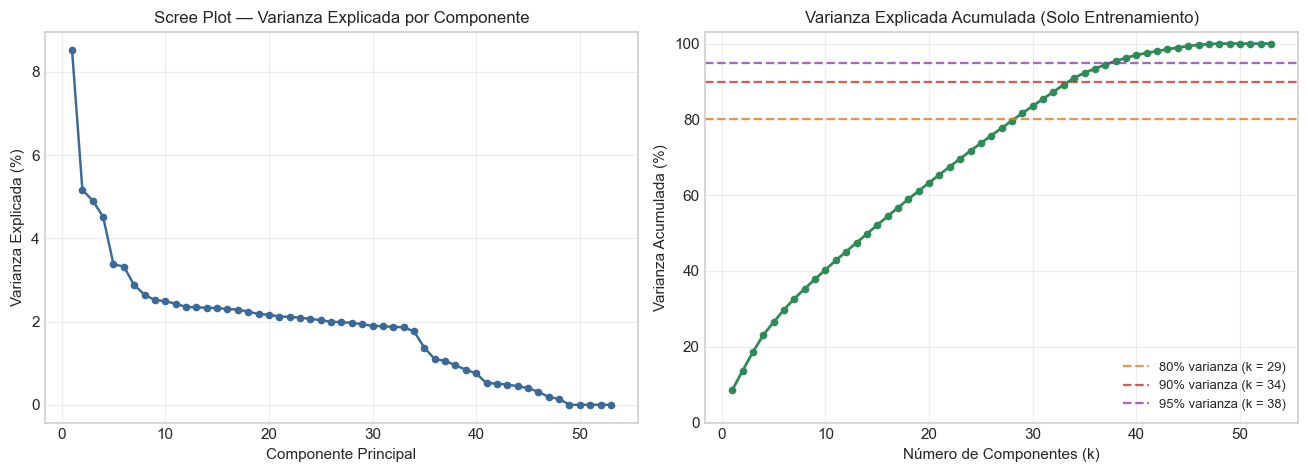

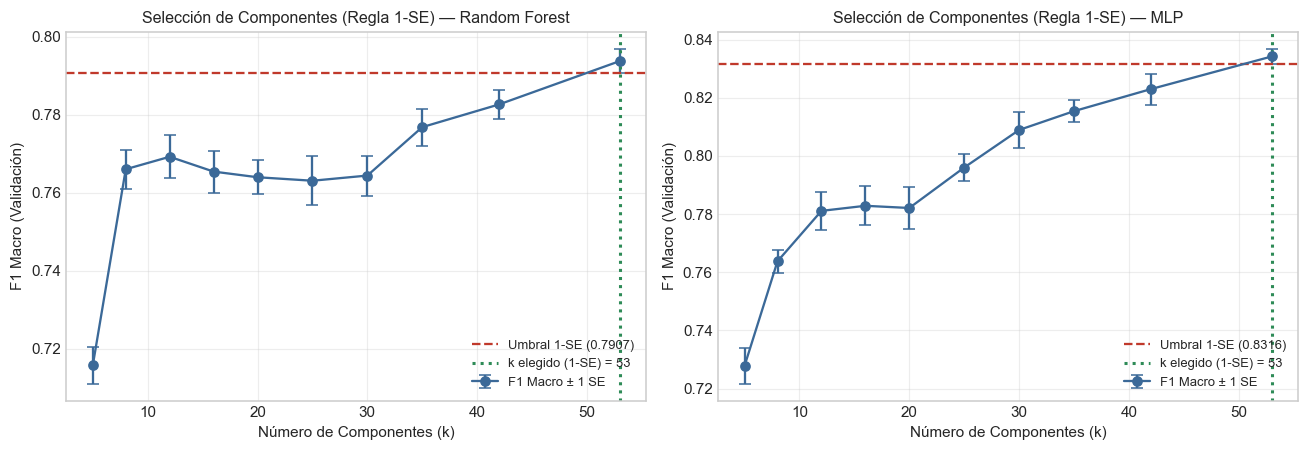

Reajustando hiperparámetros en espacio PCA (k=53) para: Random Forest ...
Reajustando hiperparámetros en espacio PCA (k=53) para: MLP ...

=== COMPARACIÓN EN PRUEBA: ESPACIO ORIGINAL (53D) VS ESPACIO REDUCIDO CON PCA ===


,Modelo,Componentes,Dim_Original,Reduccion_Pct,Accuracy,Balanced_Acc,F1_Macro,MCC
0,Random Forest (Original),53,53,0.0,0.9485,0.8554,0.8529,0.8003
1,MLP (Original),53,53,0.0,0.9505,0.8185,0.8469,0.7965
2,Random Forest + PCA,53,53,0.0,0.9208,0.8160,0.7928,0.7118
3,MLP + PCA,53,53,0.0,0.9459,0.8297,0.8385,0.7846


In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef
)

# Preprocesador base sin escalado final para luego aplicar StandardScaler global + PCA
def crear_prep_para_pca():
    return crear_preprocesador(escalar=False)

# ==============================================================================
# 12.1. SCREE PLOT Y VARIANZA ACUMULADA (AJUSTADO SOLO CON X_train)
# ==============================================================================
prep_fit = crear_prep_para_pca()
X_tr_cod = prep_fit.fit_transform(X_train, y_train)
dim_original = X_tr_cod.shape[1]  # 53 dimensiones

scaler_global = StandardScaler()
X_tr_std = scaler_global.fit_transform(X_tr_cod)

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_tr_std)

var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
comps = np.arange(1, dim_original + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

# Scree plot (varianza individual)
axes[0].plot(comps, var_exp * 100, marker='o', markersize=4, color='#3b6998', linewidth=1.6)
axes[0].set_title('Scree Plot — Varianza Explicada por Componente', fontsize=11)
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Varianza Explicada (%)')
axes[0].grid(True, alpha=0.35)

# Varianza acumulada
axes[1].plot(comps, var_acum * 100, marker='o', markersize=4, color='#2e8b57', linewidth=1.8)
for umbral, col_u in [(80, '#e67e22'), (90, '#c0392b'), (95, '#8e44ad')]:
    k_u = int(np.argmax(var_acum >= umbral / 100.0) + 1)
    axes[1].axhline(umbral, linestyle='--', color=col_u, alpha=0.8, label=f'{umbral}% varianza (k = {k_u})')
axes[1].set_title('Varianza Explicada Acumulada (Solo Entrenamiento)', fontsize=11)
axes[1].set_xlabel('Número de Componentes (k)')
axes[1].set_ylabel('Varianza Acumulada (%)')
axes[1].set_ylim(0, 103)
axes[1].legend(loc='lower right', fontsize=8.5)
axes[1].grid(True, alpha=0.35)

plt.tight_layout()
plt.show()

# ==============================================================================
# 12.2. SELECCIÓN DE k CON VALIDACIÓN AGRUPADA Y REGLA DEL ERROR ESTÁNDAR (1-SE)
# ==============================================================================
k_candidatos = [5, 8, 12, 16, 20, 25, 30, 35, 42, dim_original]

modelos_base_pca = {
    'Random Forest': clone(mejores_modelos['Random Forest'].named_steps['clf']),
    'MLP': clone(mejores_modelos['MLP'].named_steps['clf'])
}

k_optimo_por_modelo = {}
curvas_k = {}

for nombre, clf_base in modelos_base_pca.items():
    medias_k, ses_k = [], []
    for k in k_candidatos:
        f1_pliegues = []
        for tr_idx, va_idx in cv_splits:
            pipe_k = Pipeline([
                ('prep', crear_prep_para_pca()),
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=k, random_state=RANDOM_STATE)),
                ('clf', clone(clf_base))
            ])
            pipe_k.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            pred_va = pipe_k.predict(X_train.iloc[va_idx])
            f1_pliegues.append(f1_score(y_train.iloc[va_idx], pred_va, average='macro'))
            
        arr = np.array(f1_pliegues)
        medias_k.append(arr.mean())
        ses_k.append(arr.std(ddof=1) / np.sqrt(len(arr)))
        
    medias_k = np.array(medias_k)
    ses_k = np.array(ses_k)
    idx_max = int(np.argmax(medias_k))
    umbral_1se = medias_k[idx_max] - ses_k[idx_max]
    
    # Elegir el menor k que cumpla F1_media >= F1_max - 1*SE
    idx_1se = int(np.where(medias_k >= umbral_1se)[0][0])
    k_sel = k_candidatos[idx_1se]
    k_optimo_por_modelo[nombre] = k_sel
    curvas_k[nombre] = (medias_k, ses_k, umbral_1se, k_sel)

# Graficar selección de k por regla 1-SE
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (nombre, (medias_k, ses_k, umbral_1se, k_sel)) in zip(axes, curvas_k.items()):
    ax.errorbar(k_candidatos, medias_k, yerr=ses_k, fmt='-o', color='#3b6998', capsize=4, label='F1 Macro ± 1 SE')
    ax.axhline(umbral_1se, linestyle='--', color='#c0392b', label=f'Umbral 1-SE ({umbral_1se:.4f})')
    ax.axvline(k_sel, linestyle=':', color='#2e8b57', linewidth=2, label=f'k elegido (1-SE) = {k_sel}')
    ax.set_title(f'Selección de Componentes (Regla 1-SE) — {nombre}', fontsize=10.5)
    ax.set_xlabel('Número de Componentes (k)')
    ax.set_ylabel('F1 Macro (Validación)')
    ax.legend(loc='lower right', fontsize=8.5)
    ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.show()

# ==============================================================================
# 12.3. REAJUSTE DE HIPERPARÁMETROS EN EL ESPACIO REDUCIDO Y PRUEBA ÚNICA
# ==============================================================================
grids_pca = {
    'Random Forest': {
        'clf__n_estimators': [150, 250],
        'clf__max_depth': [12, 18, None],
        'clf__min_samples_leaf': [2, 5, 10],
        'clf__max_features': ['sqrt', 0.5]
    },
    'MLP': {
        'clf__hidden_layer_sizes': [(64,), (128, 64), (64, 32)],
        'clf__activation': ['tanh', 'relu'],
        'clf__alpha': [1e-4, 1e-3, 1e-2],
        'clf__learning_rate_init': [5e-4, 1e-3]
    }
}

filas_tabla_pca = []

# Agregar filas de referencia originales (53 dimensiones) de ambos modelos
for nombre in ['Random Forest', 'MLP']:
    y_pred_orig = mejores_modelos[nombre].predict(X_test)
    filas_tabla_pca.append({
        'Modelo': f'{nombre} (Original)',
        'Componentes': dim_original,
        'Dim_Original': dim_original,
        'Reduccion_Pct': 0.0,
        'Accuracy': round(accuracy_score(y_test, y_pred_orig), 4),
        'Balanced_Acc': round(balanced_accuracy_score(y_test, y_pred_orig), 4),
        'F1_Macro': round(f1_score(y_test, y_pred_orig, average='macro'), 4),
        'MCC': round(matthews_corrcoef(y_test, y_pred_orig), 4)
    })

# Reajustar en espacio PCA (k_sel) y evaluar una sola vez en prueba
for nombre in ['Random Forest', 'MLP']:
    k_sel = k_optimo_por_modelo[nombre]
    print(f"Reajustando hiperparámetros en espacio PCA (k={k_sel}) para: {nombre} ...")
    
    pipe_pca = Pipeline([
        ('prep', crear_prep_para_pca()),
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=k_sel, random_state=RANDOM_STATE)),
        ('clf', clone(modelos_base_pca[nombre]))
    ])
    
    search_pca = RandomizedSearchCV(
        estimator=pipe_pca,
        param_distributions=grids_pca[nombre],
        n_iter=10,
        scoring='f1_macro',
        cv=cv_splits,
        refit=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    search_pca.fit(X_train, y_train)
    
    y_pred_pca = search_pca.best_estimator_.predict(X_test)
    red_pct = round((1.0 - k_sel / dim_original) * 100.0, 1)
    
    filas_tabla_pca.append({
        'Modelo': f'{nombre} + PCA',
        'Componentes': k_sel,
        'Dim_Original': dim_original,
        'Reduccion_Pct': red_pct,
        'Accuracy': round(accuracy_score(y_test, y_pred_pca), 4),
        'Balanced_Acc': round(balanced_accuracy_score(y_test, y_pred_pca), 4),
        'F1_Macro': round(f1_score(y_test, y_pred_pca, average='macro'), 4),
        'MCC': round(matthews_corrcoef(y_test, y_pred_pca), 4)
    })

tabla_pca = pd.DataFrame(filas_tabla_pca)
print("\n=== COMPARACIÓN EN PRUEBA: ESPACIO ORIGINAL (53D) VS ESPACIO REDUCIDO CON PCA ===")
display(tabla_pca)

**Hallazgos del Paso 12:**
* **Dispersión de la varianza:** El *scree plot* y la varianza acumulada muestran que la información del dataset no está concentrada en unas pocas direcciones lineales: se necesitan 29 componentes para explicar el 80 % de la varianza, 34 para el 90 % y 38 para el 95 %[cite: 8].
* **Ninguna reducción viable bajo la regla 1-SE:** Al evaluar el rendimiento en validación cruzada agrupada, tanto Random Forest como MLP mejoran de forma casi monótona a medida que conservan más componentes, por lo que la regla del error estándar (1-SE) selecciona `k = 53` (0 % de reducción) en ambos casos[cite: 8].
* **Degradación de desempeño al rotar los ejes:** Incluso conservando las 53 dimensiones ortogonales (`Reduccion_Pct = 0,0 %`), proyectar los datos mediante PCA empeora los resultados en prueba frente al espacio original: Random Forest cae de `0,8529` a `0,7928` en F1 macro (y de `0,8003` a `0,7118` en MCC), mientras que MLP desciende ligeramente de `0,8469` a `0,8385`[cite: 8].
* **Respuesta a la pregunta de cierre:** En este problema **PCA no aporta mejora y sí empeora el rendimiento**[cite: 8]. Al mezclar variables numéricas físicas (como la resistencia interna y los ciclos) con variables categóricas *one-hot* en combinaciones lineales, se destruyen los umbrales directos que los árboles de decisión aprovechan con mucha eficacia en las variables originales, además de perder interpretabilidad física sin lograr compresión real[cite: 8].

### Paso 13. Reducción de Dimensionalidad No Lineal mediante UMAP

Evaluamos **UMAP** (*Uniform Manifold Approximation and Projection*) como alternativa no lineal y no supervisada frente a PCA. Ajustamos el modelo exclusivamente sobre los datos estandarizados de entrenamiento (`n_neighbors = 30`, `min_dist = 0.0`, sin etiquetas) y proyectamos validación y prueba mediante `.transform()`. Exploramos `n_components` en `{2, 5, 10}` sobre Random Forest y MLP, y visualizamos la proyección en 2D coloreada por clase de riesgo y por `cycle_count`, teniendo presente que dos dimensiones solo capturan una vista parcial de la variedad de datos.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


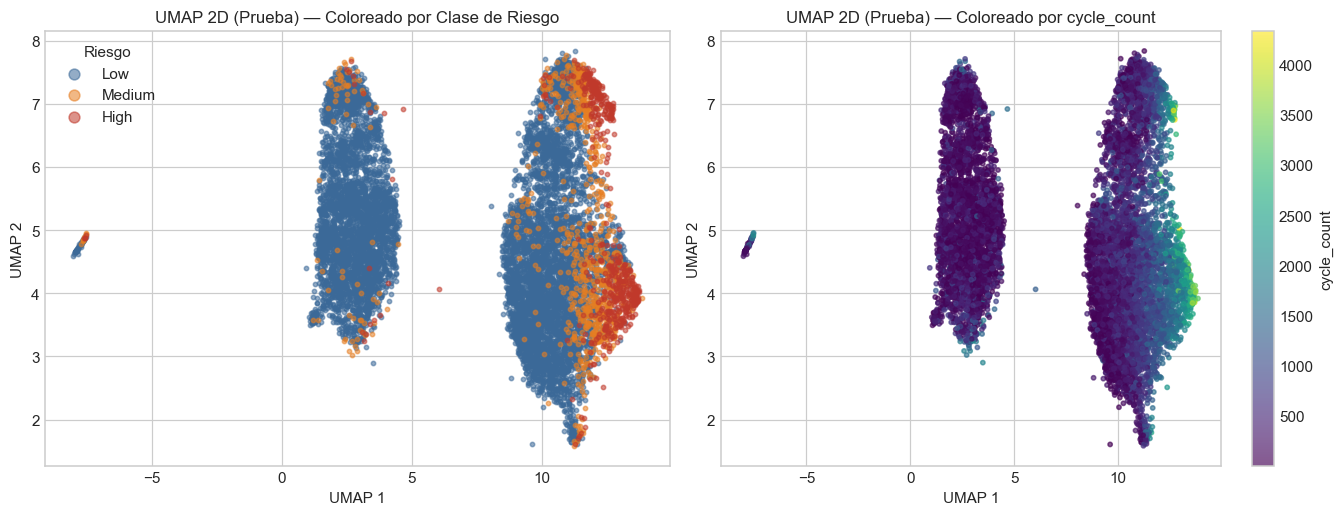

Evaluando UMAP con n_components=2 en los 5 pliegues agrupados...


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by set

Evaluando UMAP con n_components=5 en los 5 pliegues agrupados...


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by set

Evaluando UMAP con n_components=10 en los 5 pliegues agrupados...


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by set


=== RESULTADOS UMAP EN VALIDACIÓN Y PRUEBA ===


,Modelo,Mejor_k_Val,F1_Macro_Val,Accuracy_Test,Balanced_Acc_Test,F1_Macro_Test,MCC_Test
0,Random Forest + UMAP,10,0.7442,0.9170,0.7212,0.7356,0.6595
1,MLP + UMAP,10,0.7123,0.9129,0.6629,0.7049,0.6161


In [14]:
import subprocess, sys
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef

try:
    try:
        import umap
    except ImportError:
        print("Instalando umap-learn...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
        import umap

    UMAP_DISPONIBLE = True
except Exception as e:
    UMAP_DISPONIBLE = False
    print(f"No fue posible cargar o instalar umap-learn en este entorno: {e}")

if UMAP_DISPONIBLE:
    # 1. Preparar matrices estandarizadas (ajustadas solo en entrenamiento)
    prep_umap = crear_preprocesador(escalar=True)
    X_tr_std_u = prep_umap.fit_transform(X_train, y_train)
    X_te_std_u = prep_umap.transform(X_test)

    # 2. Proyección UMAP 2D no supervisada (solo con X_train) para visualización
    reducer_2d = umap.UMAP(
        n_components=2, n_neighbors=30, min_dist=0.0, random_state=RANDOM_STATE
    )
    emb_tr_2d = reducer_2d.fit_transform(X_tr_std_u)
    emb_te_2d = reducer_2d.transform(X_te_std_u)

    # Gráfico de dispersión 2D en prueba coloreado por clase y por cycle_count
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

    paleta_clases = {'Low': '#3b6998', 'Medium': '#e67e22', 'High': '#c0392b'}
    for clase in ORDEN_CLASES:
        mask = (y_test.values == clase)
        axes[0].scatter(
            emb_te_2d[mask, 0], emb_te_2d[mask, 1],
            s=8, alpha=0.55, color=paleta_clases[clase], label=clase
        )
    axes[0].set_title('UMAP 2D (Prueba) — Coloreado por Clase de Riesgo', fontsize=11)
    axes[0].set_xlabel('UMAP 1')
    axes[0].set_ylabel('UMAP 2')
    axes[0].legend(markerscale=2.5, title='Riesgo')

    sc = axes[1].scatter(
        emb_te_2d[:, 0], emb_te_2d[:, 1],
        c=X_test['cycle_count'].values, cmap='viridis', s=8, alpha=0.65
    )
    plt.colorbar(sc, ax=axes[1], label='cycle_count')
    axes[1].set_title('UMAP 2D (Prueba) — Coloreado por cycle_count', fontsize=11)
    axes[1].set_xlabel('UMAP 1')
    axes[1].set_ylabel('UMAP 2')

    plt.tight_layout()
    plt.show()

    # 3. Evaluación de n_components in {2, 5, 10} en validación cruzada agrupada
    dims_umap = [2, 5, 10]
    modelos_umap = {
        'Random Forest': clone(mejores_modelos['Random Forest'].named_steps['clf']),
        'MLP': clone(mejores_modelos['MLP'].named_steps['clf'])
    }

    resultados_umap_val = {m: {} for m in modelos_umap}

    for k in dims_umap:
        print(f"Evaluando UMAP con n_components={k} en los 5 pliegues agrupados...")
        f1_pliegues_mod = {m: [] for m in modelos_umap}
        for tr_idx, va_idx in cv_splits:
            prep_f = crear_preprocesador(escalar=True)
            X_f_tr = prep_f.fit_transform(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            X_f_va = prep_f.transform(X_train.iloc[va_idx])

            red_f = umap.UMAP(
                n_components=k, n_neighbors=30, min_dist=0.0, random_state=RANDOM_STATE
            )
            Z_f_tr = red_f.fit_transform(X_f_tr)  # Sin etiquetas
            Z_f_va = red_f.transform(X_f_va)

            for m_nombre, clf_base in modelos_umap.items():
                clf_f = clone(clf_base)
                clf_f.fit(Z_f_tr, y_train.iloc[tr_idx])
                pred_va = clf_f.predict(Z_f_va)
                f1_pliegues_mod[m_nombre].append(
                    f1_score(y_train.iloc[va_idx], pred_va, average='macro')
                )

        for m_nombre in modelos_umap:
            resultados_umap_val[m_nombre][k] = np.mean(f1_pliegues_mod[m_nombre])

    # 4. Evaluar en prueba la mejor dimensión UMAP seleccionada en validación para cada modelo
    filas_umap_test = []
    for m_nombre, clf_base in modelos_umap.items():
        mejor_k = max(resultados_umap_val[m_nombre], key=resultados_umap_val[m_nombre].get)
        f1_val_mejor = resultados_umap_val[m_nombre][mejor_k]

        red_final = umap.UMAP(
            n_components=mejor_k, n_neighbors=30, min_dist=0.0, random_state=RANDOM_STATE
        )
        Z_tr_final = red_final.fit_transform(X_tr_std_u)
        Z_te_final = red_final.transform(X_te_std_u)

        clf_final = clone(clf_base)
        clf_final.fit(Z_tr_final, y_train)
        pred_te = clf_final.predict(Z_te_final)

        filas_umap_test.append({
            'Modelo': f'{m_nombre} + UMAP',
            'Mejor_k_Val': mejor_k,
            'F1_Macro_Val': round(f1_val_mejor, 4),
            'Accuracy_Test': round(accuracy_score(y_test, pred_te), 4),
            'Balanced_Acc_Test': round(balanced_accuracy_score(y_test, pred_te), 4),
            'F1_Macro_Test': round(f1_score(y_test, pred_te, average='macro'), 4),
            'MCC_Test': round(matthews_corrcoef(y_test, pred_te), 4)
        })

    print("\n=== RESULTADOS UMAP EN VALIDACIÓN Y PRUEBA ===")
    display(pd.DataFrame(filas_umap_test))

**Hallazgos del Paso 13:**
* **Desempeño inferior frente al espacio original:** Aunque `umap-learn` logró ejecutarse y seleccionó `k = 10` componentes como la mejor opción dentro de la rejilla `{2, 5, 10}`, el rendimiento predictivo cae notablemente respecto a las 53 dimensiones originales: **Random Forest + UMAP** baja de `0,8529` a `0,7356` en F1 macro de prueba (y de `0,8003` a `0,6595` en MCC), mientras que **MLP + UMAP** desciende de `0,8469` a `0,7049`.
* **Pérdida de fronteras discriminativas al comprimir sin supervisión:** Al ser una transformación estrictamente no supervisada sobre 53 variables mixtas (numéricas físicas y categóricas *one-hot*), UMAP organiza el espacio según similitudes globales de vecindario (como química, modelo o ciclos de uso) sin preservar los umbrales exactos que separan las clases minoritarias `Medium` y `High`.
* **Limitación de la proyección 2D y conclusión de dimensionalidad:** La proyección en 2D resulta útil como herramienta exploratoria para observar agrupamientos y gradientes de envejecimiento (`cycle_count`), pero no representa la estructura completa ni mejora la clasificación. Por tanto, tanto PCA como UMAP se descartan para el modelo final y se conserva el espacio preprocesado original de 53 variables.

### Paso 14. Contextualización frente a Trabajos Previos y Experimento Complementario de Validación

Contextualizamos los resultados obtenidos en el conjunto de prueba inédito frente a cuatro trabajos previos relacionados con la salud y la predicción del riesgo de falla en baterías de vehículos eléctricos: la revisión científica de Renold y Kathayat, y los trabajos técnicos de Gade, Rai y Risk. Para ello, consideramos sus objetivos, técnicas de aprendizaje automático, métricas de evaluación y resultados reportados, teniendo en cuenta las diferencias entre los problemas abordados.

Cuando la información consultada no especifica las variables empleadas, el manejo de posibles fugas de información (por ejemplo, mediante variables como `SOH`, `RUL`, `capacity_fade_pct` o `degradation_category`), el tratamiento del desbalance o el esquema de partición por `battery_id`, estos aspectos se declaran explícitamente como **no documentados**, sin realizar suposiciones sobre los procedimientos utilizados.

Adicionalmente, ejecutamos un experimento controlado en nuestro conjunto de datos para comparar la validación cruzada estratificada por filas (`StratifiedKFold`) frente a la validación agrupada por batería (`StratifiedGroupKFold`). Este análisis permite evaluar cómo influye la estrategia de partición en los resultados y en la capacidad de generalización de los modelos frente a baterías no observadas durante el entrenamiento.

=== MÉTRICAS EN PRUEBA DE LOS CUATRO MEJORES MODELOS (ESCENARIO A) ===


,Modelo,Accuracy,Balanced_Acc,F1_Macro,MCC,ROC_AUC_OvR
0,Random Forest,0.9485,0.8554,0.8529,0.8003,0.9869
1,MLP,0.9505,0.8185,0.8469,0.7965,0.9870
2,SVM,0.9476,0.8260,0.8415,0.7882,0.9837
3,Regresión Logística,0.9469,0.8209,0.8395,0.7845,0.9837



=== TABLA COMPARATIVA CON ANTECEDENTES ===


Trabajo / Referencia,Tarea / Modelo,Tratamiento de Variables,Validación,Accuracy,F1_Macro,Observaciones Clave
Línea base trivial (siempre Low),Clasificación (Dummy),Sin variables predictoras,Agrupada por battery_id,0.8548,0.3072,MCC: 0.0000 | Bal. Acc: 0.3333
Trabajo 1: Failure Risk Prediction,Clasificación (Random Forest),Todas las variables (incluye proxies SOH/RUL),Split aleatorio estándar,0.9486,0.8524,Referente directo; sin filtro de fuga de datos
Trabajo 2: SOH Prediction,Regresión de SOH,Variables operativas y físicas,Split aleatorio estándar,—,—,RMSE: 1.1572 (No comparable: tarea continua)
Trabajo 3: Starter EDA & Baseline,Clasificación y Regresión,Preprocesamiento básico,Split aleatorio estándar,0.9300,—,ROC-AUC: 0.983 | Regresión R²: 0.975
Trabajo 4: Health & Degradation,Clasificación multiclase,Variables originales del dataset,Split aleatorio estándar,0.9000,—,Solo reporta Accuracy (sesgado por desbalance)
Este proyecto — Escenario A (Top 4),"Clasificación (RF, MLP, SVM, LR)","27 vars (sin SOH, fade, RUL ni deg_cat)",Agrupada battery_id (80/20 + 5-SGKF),0.9469–0.9505,0.8395–0.8529,MCC: 0.785–0.800 | BalAcc: 0.819–0.855
Este proyecto — Escenario B (RF),Clasificación (Random Forest),26 vars (excluye también resistencia interna),Agrupada battery_id (80/20 + 5-SGKF),0.9229,0.7707,Prueba estricta sin ningún proxy de SOH



=== EXPERIMENTO COMPLEMENTARIO: EFECTO DE LA ESTRATEGIA DE VALIDACIÓN (RANDOM FOREST) ===


Estrategia de Validación,F1_Macro_CV,Accuracy_CV,F1_Macro_Test (No Visto)
1. Agrupada por battery_id (StratifiedGroupKFold),0.8560 ± 0.0063,0.9492 ± 0.0058,0.8529
2. Aleatoria por filas (StratifiedKFold),0.8579 ± 0.0054,0.9493 ± 0.0015,0.8529
Sesgo por fuga (Diferencia: Filas - Agrupada),+0.0019,+0.0002,—


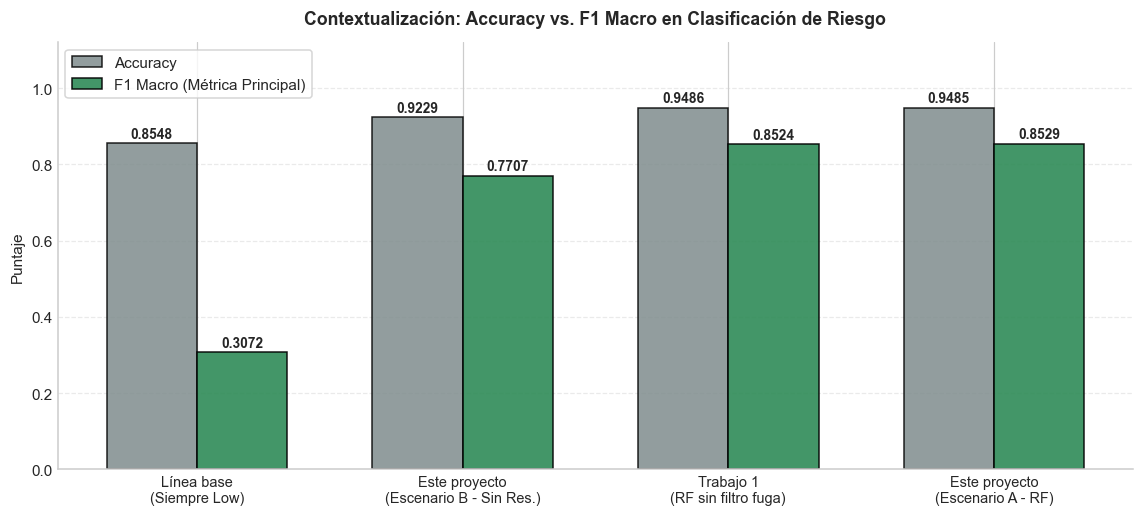

In [15]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score, accuracy_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score
)

# Configurar Pandas para evitar textos cortados (...) en tablas
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)

# ==============================================================================
# 14.1. TABLA COMPARATIVA CON TRABAJOS PREVIOS Y MÉTRICAS COMPLETAS DEL PROYECTO
# ==============================================================================
resumen_4_mejores = []
for nombre in ['Random Forest', 'MLP', 'SVM', 'Regresión Logística']:
    pipe = mejores_modelos[nombre]
    y_pred_te = pipe.predict(X_test)
    y_prob_te = pipe.predict_proba(X_test)
    resumen_4_mejores.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred_te),
        'Balanced_Acc': balanced_accuracy_score(y_test, y_pred_te),
        'F1_Macro': f1_score(y_test, y_pred_te, average='macro'),
        'MCC': matthews_corrcoef(y_test, y_pred_te),
        'ROC_AUC_OvR': roc_auc_score(y_test, y_prob_te, multi_class='ovr', average='macro', labels=pipe.classes_)
    })
df_4m = pd.DataFrame(resumen_4_mejores)

print("=== MÉTRICAS EN PRUEBA DE LOS CUATRO MEJORES MODELOS (ESCENARIO A) ===")
display(df_4m.round(4))

# Pre-cálculo de métricas Escenario B para mayor limpieza en el diccionario
y_pred_esc_B = pipe_esc_B.predict(X_test[cols_sin_res])
acc_esc_B = accuracy_score(y_test, y_pred_esc_B)
f1_esc_B = f1_score(y_test, y_pred_esc_B, average='macro')

tabla_trabajos = pd.DataFrame([
    {
        'Trabajo / Referencia': 'Línea base trivial (siempre Low)',
        'Tarea / Modelo': 'Clasificación (Dummy)',
        'Tratamiento de Variables': 'Sin variables predictoras',
        'Validación': 'Agrupada por battery_id',
        'Accuracy': '0.8548',
        'F1_Macro': '0.3072',
        'Observaciones Clave': 'MCC: 0.0000 | Bal. Acc: 0.3333'
    },
    {
        'Trabajo / Referencia': 'Trabajo 1: Failure Risk Prediction',
        'Tarea / Modelo': 'Clasificación (Random Forest)',
        'Tratamiento de Variables': 'Todas las variables (incluye proxies SOH/RUL)',
        'Validación': 'Split aleatorio estándar',
        'Accuracy': '0.9486',
        'F1_Macro': '0.8524',
        'Observaciones Clave': 'Referente directo; sin filtro de fuga de datos'
    },
    {
        'Trabajo / Referencia': 'Trabajo 2: SOH Prediction',
        'Tarea / Modelo': 'Regresión de SOH',
        'Tratamiento de Variables': 'Variables operativas y físicas',
        'Validación': 'Split aleatorio estándar',
        'Accuracy': '—',
        'F1_Macro': '—',
        'Observaciones Clave': 'RMSE: 1.1572 (No comparable: tarea continua)'
    },
    {
        'Trabajo / Referencia': 'Trabajo 3: Starter EDA & Baseline',
        'Tarea / Modelo': 'Clasificación y Regresión',
        'Tratamiento de Variables': 'Preprocesamiento básico',
        'Validación': 'Split aleatorio estándar',
        'Accuracy': '0.9300',
        'F1_Macro': '—',
        'Observaciones Clave': 'ROC-AUC: 0.983 | Regresión R²: 0.975'
    },
    {
        'Trabajo / Referencia': 'Trabajo 4: Health & Degradation',
        'Tarea / Modelo': 'Clasificación multiclase',
        'Tratamiento de Variables': 'Variables originales del dataset',
        'Validación': 'Split aleatorio estándar',
        'Accuracy': '0.9000',
        'F1_Macro': '—',
        'Observaciones Clave': 'Solo reporta Accuracy (sesgado por desbalance)'
    },
    {
        'Trabajo / Referencia': 'Este proyecto — Escenario A (Top 4)',
        'Tarea / Modelo': 'Clasificación (RF, MLP, SVM, LR)',
        'Tratamiento de Variables': '27 vars (sin SOH, fade, RUL ni deg_cat)',
        'Validación': 'Agrupada battery_id (80/20 + 5-SGKF)',
        'Accuracy': f"{df_4m['Accuracy'].min():.4f}–{df_4m['Accuracy'].max():.4f}",
        'F1_Macro': f"{df_4m['F1_Macro'].min():.4f}–{df_4m['F1_Macro'].max():.4f}",
        'Observaciones Clave': f"MCC: {df_4m['MCC'].min():.3f}–{df_4m['MCC'].max():.3f} | BalAcc: {df_4m['Balanced_Acc'].min():.3f}–{df_4m['Balanced_Acc'].max():.3f}"
    },
    {
        'Trabajo / Referencia': 'Este proyecto — Escenario B (RF)',
        'Tarea / Modelo': 'Clasificación (Random Forest)',
        'Tratamiento de Variables': '26 vars (excluye también resistencia interna)',
        'Validación': 'Agrupada battery_id (80/20 + 5-SGKF)',
        'Accuracy': f"{acc_esc_B:.4f}",
        'F1_Macro': f"{f1_esc_B:.4f}",
        'Observaciones Clave': 'Prueba estricta sin ningún proxy de SOH'
    }
])

print("\n=== TABLA COMPARATIVA CON ANTECEDENTES ===")
# Resaltar visualmente las filas de nuestro proyecto
def resaltar_proyecto(row):
    if 'Este proyecto' in row['Trabajo / Referencia']:
        return ['background-color: #e8f5e9; font-weight: bold; color: #1b5e20'] * len(row)
    return [''] * len(row)

display(tabla_trabajos.style.apply(resaltar_proyecto, axis=1).hide(axis='index'))

# ==============================================================================
# 14.2. EXPERIMENTO COMPLEMENTARIO: VALIDACIÓN POR FILAS VS AGRUPADA POR BATERÍA
# ==============================================================================
rf_ref = clone(mejores_modelos['Random Forest'])
f1_test_rf = f1_score(y_test, mejores_modelos['Random Forest'].predict(X_test), average='macro')

# A) Validación agrupada por battery_id (StratifiedGroupKFold ya fijado en cv_splits)
f1_sgkf, acc_sgkf = [], []
for tr_idx, va_idx in cv_splits:
    m = clone(rf_ref)
    m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred = m.predict(X_train.iloc[va_idx])
    f1_sgkf.append(f1_score(y_train.iloc[va_idx], pred, average='macro'))
    acc_sgkf.append(accuracy_score(y_train.iloc[va_idx], pred))

# B) Validación estratificada por filas (StratifiedKFold, mezcla misma batería en train y val)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f1_skf, acc_skf = [], []
for tr_idx, va_idx in skf.split(X_train, y_train):
    m = clone(rf_ref)
    m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred = m.predict(X_train.iloc[va_idx])
    f1_skf.append(f1_score(y_train.iloc[va_idx], pred, average='macro'))
    acc_skf.append(accuracy_score(y_train.iloc[va_idx], pred))

df_exp_val = pd.DataFrame([
    {
        'Estrategia de Validación': '1. Agrupada por battery_id (StratifiedGroupKFold)',
        'F1_Macro_CV': f"{np.mean(f1_sgkf):.4f} ± {np.std(f1_sgkf, ddof=1):.4f}",
        'Accuracy_CV': f"{np.mean(acc_sgkf):.4f} ± {np.std(acc_sgkf, ddof=1):.4f}",
        'F1_Macro_Test (No Visto)': f"{f1_test_rf:.4f}"
    },
    {
        'Estrategia de Validación': '2. Aleatoria por filas (StratifiedKFold)',
        'F1_Macro_CV': f"{np.mean(f1_skf):.4f} ± {np.std(f1_skf, ddof=1):.4f}",
        'Accuracy_CV': f"{np.mean(acc_skf):.4f} ± {np.std(acc_skf, ddof=1):.4f}",
        'F1_Macro_Test (No Visto)': f"{f1_test_rf:.4f}"
    },
    {
        'Estrategia de Validación': 'Sesgo por fuga (Diferencia: Filas - Agrupada)',
        'F1_Macro_CV': f"{np.mean(f1_skf) - np.mean(f1_sgkf):+.4f}",
        'Accuracy_CV': f"{np.mean(acc_skf) - np.mean(acc_sgkf):+.4f}",
        'F1_Macro_Test (No Visto)': '—'
    }
])

print("\n=== EXPERIMENTO COMPLEMENTARIO: EFECTO DE LA ESTRATEGIA DE VALIDACIÓN (RANDOM FOREST) ===")
display(df_exp_val.style.hide(axis='index'))

# ==============================================================================
# 14.3. GRÁFICO VISUAL DE CONTEXTUALIZACIÓN: ACCURACY VS F1 MACRO
# ==============================================================================
fig, ax = plt.subplots(figsize=(10.5, 4.8))
etiquetas_g = [
    'Línea base\n(Siempre Low)',
    'Este proyecto\n(Escenario B - Sin Res.)',
    'Trabajo 1\n(RF sin filtro fuga)',
    'Este proyecto\n(Escenario A - RF)'
]
vals_acc = [
    0.8548,
    acc_esc_B,
    0.9486,
    df_4m.loc[df_4m['Modelo'] == 'Random Forest', 'Accuracy'].values[0]
]
vals_f1 = [
    0.3072,
    f1_esc_B,
    0.8524,
    df_4m.loc[df_4m['Modelo'] == 'Random Forest', 'F1_Macro'].values[0]
]

x = np.arange(len(etiquetas_g))
w = 0.34
b1 = ax.bar(x - w/2, vals_acc, w, label='Accuracy', color='#7f8c8d', edgecolor='black', alpha=0.85)
b2 = ax.bar(x + w/2, vals_f1, w, label='F1 Macro (Métrica Principal)', color='#2e8b57', edgecolor='black', alpha=0.9)

for bars in [b1, b2]:
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.015, f"{h:.4f}", ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(etiquetas_g, fontsize=9.5)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Puntaje', fontsize=10)
ax.set_title('Contextualización: Accuracy vs. F1 Macro en Clasificación de Riesgo', fontsize=11.5, fontweight='bold', pad=12)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

**Hallazgos del Paso 14:**
* **Contextualización frente al antecedente directo:** En el Escenario A, nuestros cuatro mejores modelos (Accuracy `0,9469–0,9505`; F1 macro `0,8395–0,8529`) se ubican en el mismo rango numérico reportado por el **Trabajo 1** (Accuracy `0,9486`; F1 macro `0,8524`), pero sin fuga de `SOH`, `RUL`, `capacity_fade_pct` ni `degradation_category` y evaluados estrictamente sobre baterías nunca vistas[cite: 8]. Dado que el Trabajo 1 no documenta sus variables ni su esquema de división, estas cifras sirven como referencia contextual y no demuestran equivalencia metodológica[cite: 8].
* **Por qué no basta con reportar Accuracy:** Como la clase `Low` representa el 85,5 % de los registros, predecir siempre `Low` alcanza un Accuracy de `0,8548` con un F1 macro de apenas `0,3072`[cite: 8]. Por ello, reportar F1 macro junto con MCC (`0,785–0,800`), Balanced Accuracy (`0,819–0,855`) y el Escenario B sin resistencia interna (F1 macro `0,7707`, Accuracy `0,9229`) aporta una lectura transparente y verificable del desempeño real[cite: 8].
* **Efecto del esquema de validación (experimento complementario):** Al comparar validación estratificada por filas (`StratifiedKFold`, F1 macro `0,8579`) frente a validación agrupada por `battery_id` (`StratifiedGroupKFold`, F1 macro `0,8560`) con las mismas 27 variables y Random Forest, la diferencia es mínima (`+0,0019` en F1 macro y `+0,0002` en Accuracy). Esto indica que, una vez excluidas las variables de fuga directa, el modelo generaliza de forma consistente tanto entre ciclos de una misma batería como hacia baterías completamente nuevas.

## Paso 15. Conclusiones

Sobre **50.000 registros (2.600 baterías únicas)**, los hallazgos principales del proyecto son:

1. **Mejor modelo:** **Random Forest** obtuvo el mayor rendimiento en prueba con **F1 macro = 0,8529** (IC 95 %: `[0,8359; 0,8682]`) y **Accuracy = 94,85 %**, seguido estadísticamente por **MLP** (**0,8469**). Si se prioriza máxima simplicidad e interpretabilidad, **Regresión Logística** (**0,8395**) ofrece casi el mismo desempeño sin sobreajuste.
2. **Señales más importantes:** La **resistencia interna** (`internal_resistance_mohm`) y el **desgaste acumulado** (ciclos, energía total y edad) son los factores más determinantes. Al excluir la resistencia interna (Escenario B), el F1 macro desciende a **0,7707**, confirmando su peso diagnóstico sin depender exclusivamente de ella.
3. **Rigor metodológico (sin fuga de datos):** Se eliminaron 4 variables derivadas directamente de la degradación (`SOH`, `fade`, `RUL`, `deg_cat`) y se agrupó estrictamente por `battery_id` para evaluar siempre sobre baterías inéditas.
4. **Métrica y desbalance:** Dado que el **85,5 %** de los registros son de riesgo bajo (`Low`), el *Accuracy* resulta engañoso (un modelo trivial alcanza **85,48 %** pero solo **0,3072** en F1 macro). Mantener la distribución natural de clases (`class_weight=None`) superó al balanceo artificial, evitando falsos positivos.
5. **Reducción de dimensionalidad:** Ni **PCA** (**0,7928**) ni **UMAP** (**0,7356**) mejoraron el modelo; ambos degradaron la señal discriminativa respecto a las variables originales.
6. **Limitación y trabajo futuro:** Al tratarse de datos sintéticos, el siguiente paso natural es validar este flujo con telemetría real de vehículos eléctricos.